# Stress Testing a Markovitz Portfolio

## Introduction

This project investigates how to construct and dynamically manage a Minimum Variance Portfolio (MVP) using two selected financial assets. The goal is to determine the optimal allocation of capital between the two assets in a way that minimizes overall portfolio risK. This allocation is updated daily to reflect changing market conditions, ensuring the portfolio consistently maintains the lowest possible risk profile.

The proposed methodology involves computing a daily covariance matrix of asset returns to estimate their evolving correlation structure. Based on this matrix, the portfolio weights are recalculated each day to maintain the minimum variance configuration. A key focus is on evaluating Value at Risk (VaR) and Expected Shortfall (ES) at a 95% confidence level, particularly during periods of market stress.

A central challenge of this work is ensuring that the model performs robustly during high-volatility periods, such as those observed during 2024-2025. To address this, several risk modeling and forecasting techniqes were tested, with particular attention given to their peformance under stress scenarios. The objective is to develop a model that accurately predicts portfolio risk and supports effective asset allocation, even in turbolent market conditions.

Ultimately, this project aims to create an AI-driven system capable of cinstructing and managing a Minimum Variance Portfolio that adapts dynamically to market conditions, minimizing risk exposure while remaining responsive to extreme financial stress.

### Importing necessary Libraries

In [55]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import seaborn as sns
import math

### Defining necessary Functions

In [56]:
def compute_cov_matrices(returns, window_size):
  """
  Compute covariance matrices for given returns using a rolling window
  """

  cov_matrices = []

  for i in range(window_size, len(returns)):
      window_returns = returns.iloc[i-window_size:i]
      cov_matrix = window_returns.cov().values

      date = returns.index[i]

      cov_matrices.append((date, cov_matrix))
  return cov_matrices

In [57]:
def compute_mvp_weights(cov_matrices):
  """
  Computes the minimum variance portfolio weights using the given covariance matrices
  """
  mvp_weights = []
  dates = []

  for date, sigma_t in cov_matrices:
    var_pfe = sigma_t[0,0]
    var_rhm = sigma_t[1,1]
    cov_pr = sigma_t[0,1]

    denom = var_pfe + var_rhm - 2 * cov_pr

    if denom != 0:
      w_pfe = (var_rhm - cov_pr) / denom
    else:
      w_pfe = 0.5
    w_rhm = 1 - w_pfe

    mvp_weights.append((w_pfe, w_rhm))
    dates.append(date)

  # Create dataframe to store weights
  mvp_weights_df = pd.DataFrame(mvp_weights, columns=['w_pfe', 'w_rhm'], index=dates)

  return mvp_weights_df


def compute_mvp_value_quantities(mvp_weights_df, returns, capital, train_pfe, train_rhm):

  portfolio_values = []
  holdings_pfe = []
  holdings_rhm = []
  quantities_pfe = []
  quantities_rhm = []

  for i in range(len(mvp_weights_df)):
    # Extract weights for current date
    date = mvp_weights_df.index[i]
    w_pfe = mvp_weights_df.iloc[i, 0]
    w_rhm = mvp_weights_df.iloc[i, 1]

    daily_returns = returns.loc[date]

    r_pfe = daily_returns['pfe']
    r_rhm = daily_returns['rhm']

    portfolio_return = w_pfe * r_pfe + w_rhm * r_rhm

    # Update portfolio value
    if i == 0:
      portfolio_value = capital * (1 + portfolio_return)
    else:
      previous_portfolio_value = portfolio_values[-1]
      portfolio_value = previous_portfolio_value * (1 + portfolio_return)

    portfolio_values.append(portfolio_value)


    q_pfe = (portfolio_value * w_pfe) / train_pfe["Close"].loc[date]
    q_rhm = (portfolio_value * w_rhm) / train_rhm["Close"].loc[date]

    holdings_pfe.append(q_pfe)
    holdings_rhm.append(q_rhm)

    if i > 0:
      quantities_pfe.append(holdings_pfe[i] - holdings_pfe[i-1])
      quantities_rhm.append(holdings_rhm[i] - holdings_rhm[i-1])
    else:
      quantities_pfe.append(0)
      quantities_rhm.append(0)

  # Convert back to dataframe
  quantities_pfe = pd.Series(quantities_pfe, index=mvp_weights_df.index)
  quantities_rhm = pd.Series(quantities_rhm, index=mvp_weights_df.index)

  return portfolio_values, quantities_pfe, quantities_rhm

In [58]:
def compute_normal_var_es(mvp_weights_df, returns, cov_matrices, confidence_level=0.95):
    """
    Compute Value at Risk (VaR) and Expected Shortfall (ES) under normality assumption.
    """
    z = norm.ppf(confidence_level)
    phi_z = norm.pdf(z)

    VaRs = []
    ESs = []

    for i, date in enumerate(mvp_weights_df.index):
        w = np.array(mvp_weights_df.iloc[i])
        mu = np.dot(w, returns.loc[date])  # Expected portfolio return

        sigma_t = cov_matrices[i][1]       # Covariance matrix
        sigma = np.sqrt(w @ sigma_t @ w.T) # Portfolio std deviation

        # Parametric VaR and ES
        VaR = -(mu - z * sigma)
        ES = -(mu - sigma * phi_z / (1 - confidence_level))

        VaRs.append(VaR)
        ESs.append(ES)

    risk_df = pd.DataFrame({'VaR': VaRs, 'ES': ESs}, index=mvp_weights_df.index)
    return risk_df


def historical_var_es(portfolio_returns, window, confidence_level=0.95):
    """
    Compute historical VaR and ES for given returns using rolling window
    """
    VaRs_historical = []
    ESs_historical = []
    hs_dates = portfolio_returns.index[window:]

    # Compute historical VaR and ES
    for i in range(window, len(portfolio_returns)):

      returns_window = portfolio_returns.iloc[i-window:i]

      sorted_returns = returns_window.sort_values()

      VaR = np.percentile(sorted_returns, 5)
      ES = sorted_returns[sorted_returns <= VaR].mean()

      VaRs_historical.append(-VaR)
      ESs_historical.append(-ES)

    VaR_series_historical = pd.Series(VaRs_historical, index=hs_dates)
    ES_series_historical = pd.Series(ESs_historical, index=hs_dates)

    return VaR_series_historical, ES_series_historical


def stress_var_es(portfolio_returns, window, stress_threshold, stress_multiplier, confidence_level=0.95):
    """
    Compute stressed VaR and ES for given returns using rolling window
    """
    VaRs_stress = []
    ESs_stress = []
    stress_dates = portfolio_returns.index[window:]

    # Loop over rolling window
    for i in range(window, len(portfolio_returns)):
      returns_window = portfolio_returns.iloc[i-window:i]

      # Compute volatility
      rolling_vol = returns_window.rolling(20).std()

      # Identify high-volatility days in the window
      stressed_returns = returns_window.copy()
      stressed_returns[rolling_vol > stress_threshold] *= stress_multiplier

      # Sort
      sorted_returns = stressed_returns.sort_values()

      # Compute VaR and ES
      VaR = np.percentile(sorted_returns, 5)
      es = sorted_returns[sorted_returns <= VaR].mean()

      VaRs_stress.append(-VaR)
      ESs_stress.append(-es)

    VaR_series_stress = pd.Series(VaRs_stress, index=stress_dates)
    ES_series_stress = pd.Series(ESs_stress, index=stress_dates)

    return VaR_series_stress, ES_series_stress

def stressed_var_es_z_threshold(portfolio_returns, window, stress_multiplier, z_threshold, confidence_level=0.95):

    VaRs_stress = []
    ESs_stress = []
    stress_dates = portfolio_returns.index[window:]

    for i in range(window, len(portfolio_returns)):
      returns_window = portfolio_returns.iloc[i - window:i]

      # Compute 20-day rolling volatility
      rolling_vol = returns_window.rolling(window).std()

      # Compute mean and standard violatility within the window
      vol_mean = rolling_vol.mean()
      vol_std = rolling_vol.std()

      # Z-score for each point's volatility
      z_scores = (rolling_vol - vol_mean) / vol_std

      # Check stress condition
      stress_flags = z_scores > z_threshold

      # Apply stress amplification
      stressed_returns = returns_window.copy()
      stressed_returns[stress_flags] *= stress_multiplier

      # Compute VaR and ES from stressed returns
      sorted_returns = stressed_returns.sort_values()
      VaR = np.percentile(sorted_returns, 5)
      es = sorted_returns[sorted_returns <= VaR].mean()

      VaRs_stress.append(-VaR)
      ESs_stress.append(-es)

    # Create result series
    VaR_series_stress_z_threshold = pd.Series(VaRs_stress, index=stress_dates)
    ES_series_stress_z_threshold = pd.Series(ESs_stress, index=stress_dates)

    return VaR_series_stress_z_threshold, ES_series_stress_z_threshold

In [59]:
def compute_var_violation_rate(actual_returns, predicted_var):
  """
  Returns the percentage od days where the actual loss exceeded predicted VaR.
  """

  actual_returns, predicted_var = actual_returns.align(predicted_var, join='inner')
  actual_returns = actual_returns.dropna()
  predicted_var = predicted_var.loc[actual_returns.index]
  violations = actual_returns < -predicted_var
  violation_rate = violations.mean() * 100

  return violation_rate, violations

def compute_actual_es(actual_returns, violations):
  """
  Compute average returns on days where VaR was violated.
  """

  if(violations.sum() == 0):
    return np.nan
  else:
    return -actual_returns[violations].mean()

def evaluate_stress_model(actual_returns, predicted_var, predicted_es):
  """
  Evaluate the performance of the stress model.
  """

  actual_returns, predicted_var = actual_returns.align(predicted_var, join='inner')
  _, predicted_es = actual_returns.align(predicted_es, join='inner')

  var_violation_rate, violations = compute_var_violation_rate(actual_returns, predicted_var)
  actual_es = compute_actual_es(actual_returns, violations)

  return [var_violation_rate, actual_es, predicted_es.values.mean()]

In [60]:
def var_es_param_grid_search(portfolio_returns, window_sizes, stress_thresholds=[0.002], stress_multipliers=[2], z_thresholds=[2], key="historical"):

  if not key in ["historical", "stress", "z_threshold"]:
    raise ValueError("Key must be either 'historical', 'stress', or 'z_threshold'.")

  param_metrics = []

  if key == "historical":
    for window in window_sizes:
      print("Current window: ", window)
      VaR_series_historical, ES_series_historical = historical_var_es(portfolio_returns, window)
      metrics = evaluate_stress_model(portfolio_returns, VaR_series_historical, ES_series_historical)
      param_metrics.append({"window": window, "VaR Violation Rate": metrics[0], "Actual ES": metrics[1], "Predicted ES": metrics[2]})
  elif key == "stress":
    for window in window_sizes:
      print("Current window: ", window)
      for stress_threshold in stress_thresholds:
        for stress_multiplier in stress_multipliers:
          VaR_series_stress, ES_series_stress = stress_var_es(portfolio_returns, window, stress_threshold, stress_multiplier)
          metrics = evaluate_stress_model(portfolio_returns, VaR_series_stress, ES_series_stress)
          param_metrics.append({"window": window, "stress_threshold": stress_threshold, "stress_multiplier": stress_multiplier, "VaR Violation Rate": metrics[0], "Actual ES": metrics[1], "Predicted ES": metrics[2]})
  elif key == "z_threshold":
    for window in window_sizes:
      print("Current window: ", window)
      for stress_multiplier in stress_multipliers:
        for z_threshold in z_thresholds:
          VaR_series_stress_z_threshold, ES_series_stress_z_threshold = stressed_var_es_z_threshold(portfolio_returns, window, stress_multiplier, z_threshold)
          metrics = evaluate_stress_model(portfolio_returns, VaR_series_stress_z_threshold, ES_series_stress_z_threshold)
          param_metrics.append({"window": window, "stress_multiplier": stress_multiplier, "z_threshold": z_threshold, "VaR Violation Rate": metrics[0], "Actual ES": metrics[1], "Predicted ES": metrics[2]})

  return pd.DataFrame(param_metrics)


In [61]:
def find_best_params(param_metrics, key="historical", weight=0.6):
  if not key in ["historical", "stress", "z_threshold"]:
    raise ValueError("Key must be either 'historical', 'stress', or 'z_threshold'.")

  best_params = []

  best_value = float('inf')
  best_window = 0
  best_stress_threshold = 0
  best_stress_multiplier = 0
  best_z_threshold = 0

  if key == "historical":
    for _, row in param_metrics.iterrows():
      if (np.abs(row["VaR Violation Rate"] - 5)*weight + np.abs(row["Actual ES"] - row["Predicted ES"])) < best_value:
        best_actual_var = np.abs(row["VaR Violation Rate"] - 5)
        best_window = row["window"]
    best_params.append({"window": best_window})

  elif key == "stress":
    for _, row in param_metrics.iterrows():
      if (np.abs(row["VaR Violation Rate"] - 5)*weight + np.abs(row["Actual ES"] - row["Predicted ES"])) < best_value:
        best_actual_var = np.abs(row["VaR Violation Rate"] - 5)
        best_window = row["window"]
        best_stress_threshold = row["stress_threshold"]
        best_stress_multiplier = row["stress_multiplier"]
    best_params.append({"window": best_window, "stress_threshold": best_stress_threshold, "stress_multiplier": best_stress_multiplier})

  elif key == "z_threshold":
    for _, row in param_metrics.iterrows():
      if (np.abs(row["VaR Violation Rate"] - 5)*weight + np.abs(row["Actual ES"] - row["Predicted ES"])) < best_value:
        best_actual_var = np.abs(row["VaR Violation Rate"] - 5)
        best_window = row["window"]
        best_stress_multiplier = row["stress_multiplier"]
        best_z_threshold = row["z_threshold"]
    best_params.append({"window": best_window, "stress_multiplier": best_stress_multiplier, "z_threshold": best_z_threshold})

  return best_params


### Data Collection and Preparation

The period analyzed in this project spans from 2010 to 2025, with historical data from 2010 to 2023 used for model training and calibration. This timeframe includes two major geopolitical and economic events that significantly impacted global markets: the COVID-19 pandemic in 2020 and the Russian invasion of Ukrain in 2022.

In light of these events, **Pfizer and Rheinmetall** were selected as the two assets for portfolio construction. Pfizer, a global pharmaceutical company, played a central role during the pandemic through the development and distribution of COVID-19 vaccines. As a result, its stock performance reflects mmarket dynamics and investor sentiment during a global health crisis. On the other hand, Rheinmetall, a leading German defense contractor, experienced increased demand and investor interest in response to rising geopolitical tensions and the European rearmament push following the Ukraine conflict.

These two companies were chosen because they represent sector (healthcare and defense) that are directly linked to major karket stressors within the chosen timeframe. Their performance offers valuable insights into how different sectors respond to global crises, making them ideal candidates for constructing a Minimum Variance Portfolio that is resilient in periods of heightened volatility. By selecting assets that exhibit strong and divergent responses to systemic shocks, the model is better equipped to learn and adapt to stress conditions, fulfilling the objective of risk minimization during turbolent periods such as 2024-2025.

#### Pfizer

In [62]:
# Collecting Pfizer data from yahoo finance
ticker = 'PFE'
tickers = [ticker]
raw_data_pfe = yf.download(tickers, start='2010-01-01')

# Save in csv
raw_data_pfe.to_csv('pfe.csv')

[*********************100%***********************]  1 of 1 completed


In [63]:
# Read data from csv
pfe_data_df = pd.read_csv('pfe.csv', skiprows=2)
pfe_data_df.columns = ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

# Convert and set Date index
pfe_data_df["Date"] = pd.to_datetime(pfe_data_df["Date"], errors="coerce")
pfe_data_df.set_index("Date", inplace=True)

print(pfe_data_df.columns)

pfe_data_df

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,9.683945,9.689060,9.330965,9.346311,54898644
2010-01-05,9.545823,9.683946,9.489551,9.678830,45714931
2010-01-06,9.515131,9.622560,9.469090,9.545825,43640975
2010-01-07,9.479318,9.550937,9.443508,9.535590,41557112
2010-01-08,9.556053,9.571400,9.474203,9.525360,32049716
...,...,...,...,...,...
2025-05-28,23.180000,23.639999,23.110001,23.610001,36737200
2025-05-29,23.450001,23.450001,23.160000,23.330000,26091400
2025-05-30,23.490000,23.620001,23.160000,23.480000,56618600


In [64]:
# Computing daily returns
returns = raw_data_pfe['Close']

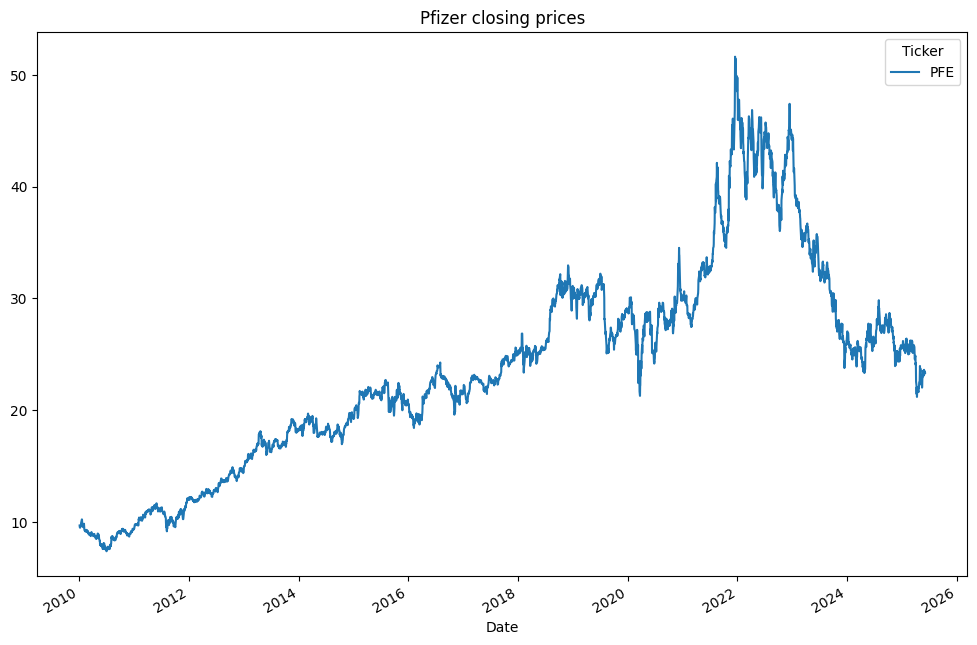

In [65]:
# Plotting daily returns
returns.plot(figsize=(12,8), title="Pfizer closing prices")
plt.show()

The plot above illustrates Pfizer's performance from 2010 to 2025, highlighting its relatively stable growth trajectory up to the onset of the COVID-19 pandemic in early 2020. As the pandemic unfolded, the stock experienced a brief downward dip, likely driven by initial market panic and uncertainty. However, this was quickly followed by a sharp upward stage, reflecting renewed investor confidence as Pfizer emerged as a key player in vaccine development. The stock reached its prak performance at the end of 2021, marking the height of pandemic-driven optimism. Following this peak, Pfizer's stock entered a gradual and steady decline, indicating a return to market normalization and reduced pandemic.related momentum, which continues through the first half of 2025.

In [66]:
# Compute Pfizer daily returns
returns_pfe = returns.pct_change()
returns_pfe.dropna(inplace=True)
returns_pfe.head()

Ticker,PFE
Date,
2010-01-05,-0.014263
2010-01-06,-0.003215
2010-01-07,-0.003764
2010-01-08,0.008095
2010-01-11,0.008030


To compute daily returns, closing prices were used, as they provide a more accurate reflection of market sentiment compared to opening prices, which can often be overly optimistic and less reliable. Returns were calculated as the percentage change between the closing price of the current day and that of the previous day. A positive return indicates a gain, meaning the asset increased in value relative to the previous day, while a negative return reflects a loss.

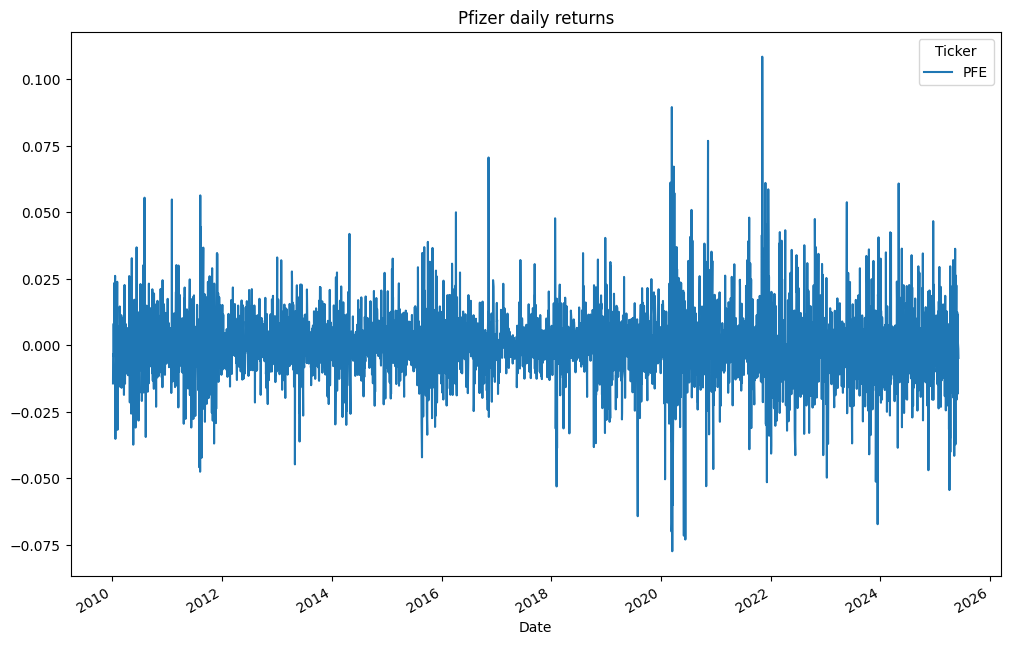

In [67]:
# plot
returns_pfe.plot(figsize=(12,8), title="Pfizer daily returns")
plt.show()

#### Rheinmetall

In [68]:
# Download Rheinmetall historical data from yahoo finance
ticker = 'RHM.DE'
tickers = [ticker]
raw_data_rhm = yf.download(ticker, start='2010-01-01')

raw_data_rhm.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,RHM.DE,RHM.DE,RHM.DE,RHM.DE,RHM.DE
Date,,,,,
2010-01-04,32.754395,33.405771,32.062989,32.386858,175457
2010-01-05,32.452362,32.896317,32.146687,32.896317,122509
2010-01-06,31.804632,32.583372,31.375233,32.583372,186449
2010-01-07,31.895603,32.008410,31.207837,31.535346,152821
2010-01-08,32.226746,32.350472,31.997491,32.161244,192174


In [69]:
# Saving data to csv
raw_data_rhm.to_csv('rhm.csv')
rhm_data_df = pd.read_csv('rhm.csv', skiprows=2)
rhm_data_df.columns = ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

rhm_data_df["Date"] = pd.to_datetime(rhm_data_df["Date"], errors="coerce")
rhm_data_df.set_index("Date", inplace=True)

print(rhm_data_df.columns)

rhm_data_df.head()

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,32.754395,33.405771,32.062989,32.386858,175457
2010-01-05,32.452362,32.896317,32.146687,32.896317,122509
2010-01-06,31.804632,32.583372,31.375233,32.583372,186449
2010-01-07,31.895603,32.008410,31.207837,31.535346,152821
2010-01-08,32.226746,32.350472,31.997491,32.161244,192174


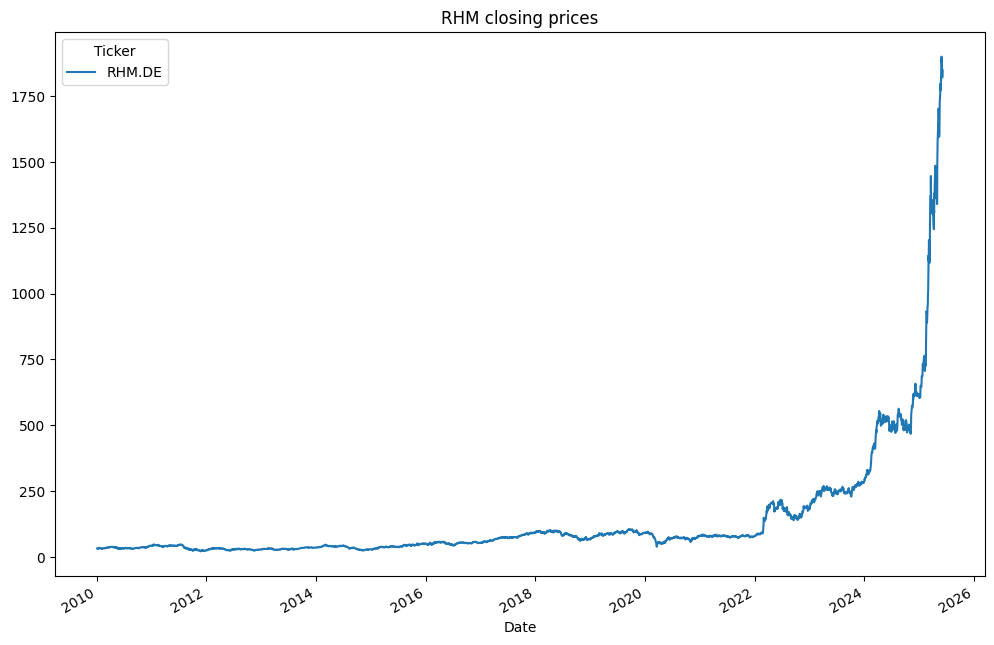

In [70]:
# plot close
raw_data_rhm['Close'].plot(figsize=(12,8), title="RHM closing prices")
plt.show()

The plot above shows the evolution of Rheinmetall's stock price over the period from 2010 to 2025. Between 2010 and early 2022, the stock remained relatively stable, showing no significant long-term trend in either direction. However, this changed dramatically with the outbreak of the Russian invasion of Ukraine in early 2022. The event triggered a sharp and sustained increase in Rheinmetall's stock price, reflecting heightened investor interest in defense and military-related sectors. The upward momentum intensified in early 2024, coinciding with a broader wave of European rearmament and increased defense spending, positioning Rheinmetall as a key beneficiary of the new geopolitical landscape.

In [71]:
# Computing Rheinmetall daily returns
returns_rhm = raw_data_rhm['Close']
daily_returns_rhm = returns_rhm.pct_change()
daily_returns_rhm.dropna(inplace=True)
daily_returns_rhm.head()

Ticker,RHM.DE
Date,
2010-01-05,-0.009221
2010-01-06,-0.019959
2010-01-07,0.002860
2010-01-08,0.010382
2010-01-11,0.009259


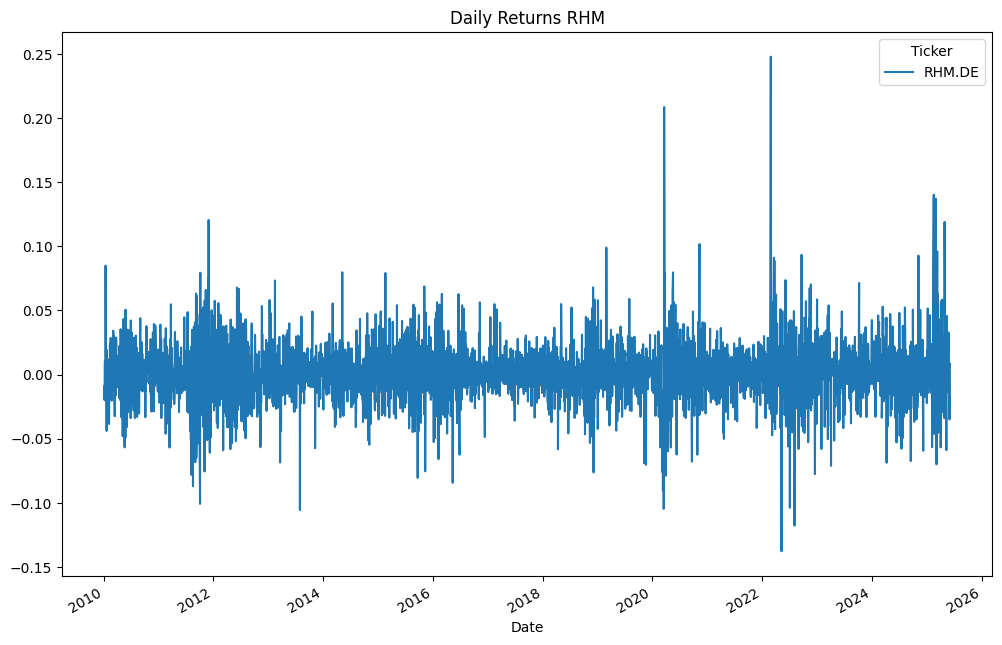

In [72]:
# Plotting daily returns
daily_returns_rhm.plot(figsize=(12,8), title="Daily Returns RHM")
plt.show()

## Training

### Splitting between Training and Testing

In [73]:
# Ensure the index is datetime
raw_data_pfe.index = pd.to_datetime(raw_data_pfe.index)
raw_data_rhm.index = pd.to_datetime(raw_data_rhm.index)

# pfe
train_pfe = raw_data_pfe['2010-01-01':'2023-12-31']
test_pfe = raw_data_pfe['2024-01-01':]

# rhm
train_rhm = raw_data_rhm['2010-01-01':'2023-12-31']
test_rhm = raw_data_rhm['2024-01-01':]

In [74]:
# Computing training daily returns
returns_train_pfe = train_pfe['Close'].pct_change()
returns_train_pfe.dropna(inplace=True)

returns_train_rhm = train_rhm['Close'].pct_change()
returns_train_rhm.dropna(inplace=True)

In [75]:
returns_train_pfe.head()

Ticker,PFE
Date,
2010-01-05,-0.014263
2010-01-06,-0.003215
2010-01-07,-0.003764
2010-01-08,0.008095
2010-01-11,0.008030


In [76]:
returns_train_rhm.head()

Ticker,RHM.DE
Date,
2010-01-05,-0.009221
2010-01-06,-0.019959
2010-01-07,0.002860
2010-01-08,0.010382
2010-01-11,0.009259


### Estimating the Covariance Matrix

The covariance matrix is a critical tool in modern portfolio theory, as it quantifies how different financial assets move in relation to one another. It provides a comprehensive snapshot of risk and correlation: the diagonal elements capture the pairwise covariances, indicating whether assets returns tend to move together or in oppositve directions.

In the context of portfolio optimization, especially when constructing a Minimum Variance Portfolio (MVP), understanding these relationships is essential. Diversification benefits arise when assets are not perfectly correlated: by combining assets with lower or negative correlations, it's possible to reduce the overall portfolio risk.

To effectively model how these relationships evolve over time (particularly during volatile or stress periods) we estimate the covariance matrix using a rolling window approach. This moethod involves computing the covariance of asset returns over a fixed-length time window that moves forward day by day. At each step, only the most recent data is used, which allows the model to remain responsive to recent market dynamics.

This adaptive process is key to managing risk in real time. Market conditions are not static: correlations between assets can shift rapidly in response to macroeconomic shocks, political events, or crises. For example, during the COVID-19 pandemic or the onset of the war in Ukraine, asset behavior changed dramatically. A static, historical estimate of the correlation would fail to capture such dynamics, potentially leading to underestimation of risk. The rolling covariance matrix, by contrast, is designed to capture these shifts, enabling the model to update its risk estimates and rebalance the portfolio accordingly.

By continuously recalculating the covariance matrix, we are able to track changes in co-movements between assets and maintain a portfolio that is dynamically optimized to minimize risk, even under highly uncertain conditions. This forms the foundation for constructing a reliable, low-rosk investment strategy that is capable of adapting to stress scenarios like those seen between 2020 and 2025.

In [77]:
# Concatenate simple daily returns into a single DataFrame
returns = pd.concat([returns_train_pfe, returns_train_rhm], axis=1).dropna()
returns.columns = ['pfe', 'rhm']
returns.head()

,pfe,rhm
Date,,
2010-01-05,-0.014263,-0.009221
2010-01-06,-0.003215,-0.019959
2010-01-07,-0.003764,0.002860
2010-01-08,0.008095,0.010382
2010-01-11,0.008030,0.009259


In [78]:
# Compute the daily covariance matrix using a window of 20 days
cov_matrices = compute_cov_matrices(returns=returns, window_size=20)

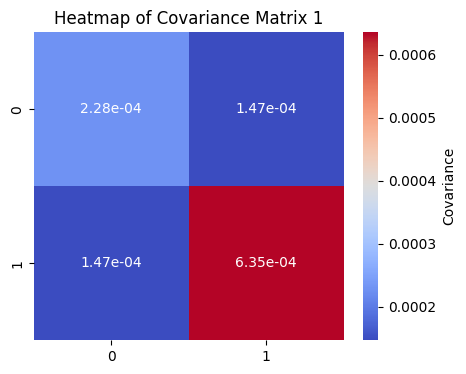

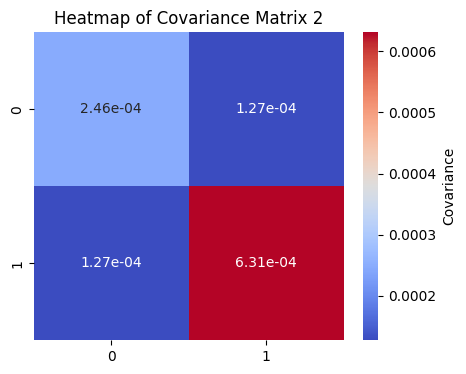

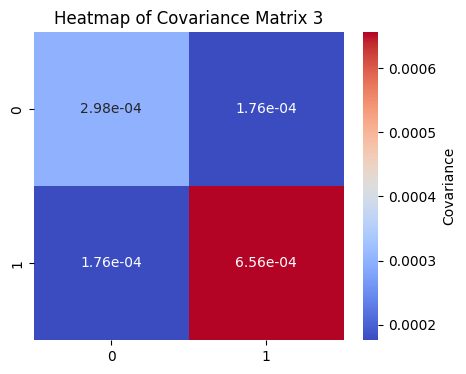

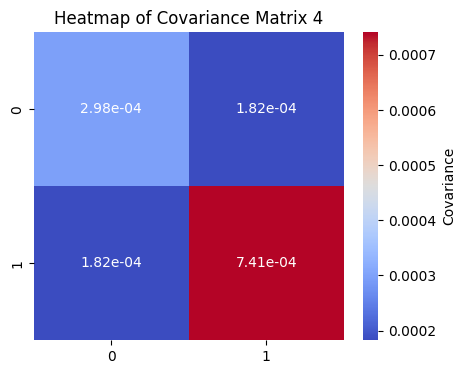

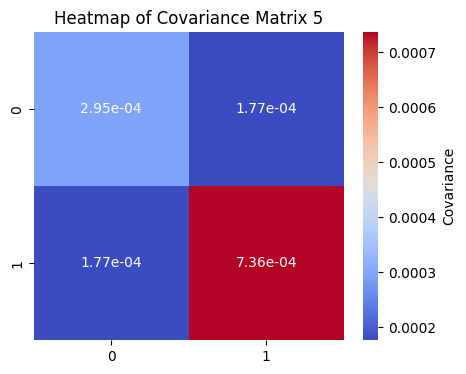

In [79]:
# Plot correlation matrices
for i, (_, sigma_t) in enumerate(cov_matrices[:5]):
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        sigma_t,
        cmap='coolwarm',
        annot=True,
        vmin=sigma_t.min(),
        vmax=sigma_t.max(),
        fmt=".2e",
        cbar_kws={'label': 'Covariance'}
    )
    plt.title(f'Heatmap of Covariance Matrix {i+1}')
    plt.show()


The heatmaps above indicate that there is minimal correlation between the two selected assets. This suggests that their price movements are largely independent of each other. This observation aligns with the behavior seen in the daily closing price plots: each asset reacts differently to major market events, with one rising while the other may remain stable or decline. This lack of significant correlation enhances their value in a diversified portfoliom as combining uncorrelated assets reduces overall risk. Their complementary behavior under stress conditions makes them particularly well-suited for contructing a robust, low-risk Minimum Variance Portfolio.

### Estimating the Minimum Variance Portfolio

In [80]:
mvp_weights_df = compute_mvp_weights(cov_matrices)
mvp_weights_df.head()

,w_pfe,w_rhm
2010-02-03,0.856836,0.143164
2010-02-04,0.809118,0.190882
2010-02-05,0.797370,0.202630
2010-02-08,0.828565,0.171435
2010-02-09,0.825594,0.174406


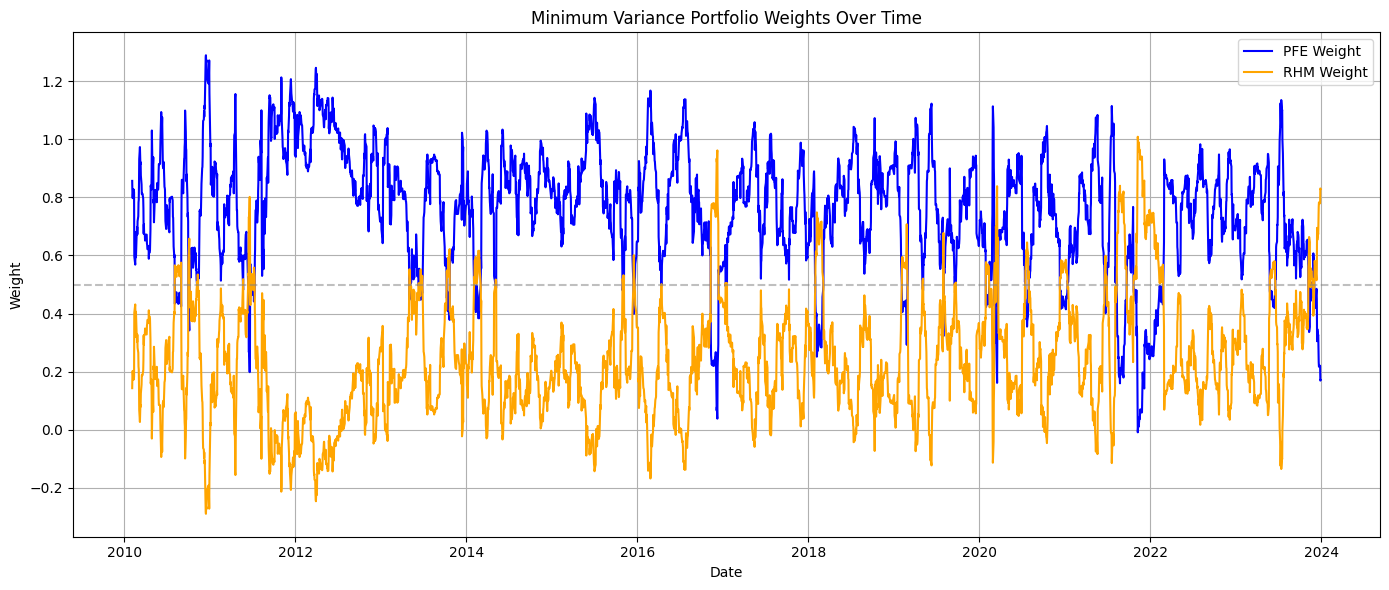

In [81]:
# Plot the weights
plt.figure(figsize=(14, 6))
plt.plot(mvp_weights_df.index, mvp_weights_df["w_pfe"], label="PFE Weight", color="blue")
plt.plot(mvp_weights_df.index, mvp_weights_df["w_rhm"], label="RHM Weight", color="orange")
plt.axhline(0.5, linestyle="--", color="gray", alpha=0.5)

plt.title("Minimum Variance Portfolio Weights Over Time")
plt.xlabel("Date")
plt.ylabel("Weight")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


The plot above illustrates the evolution of portfolio weights over time, showing how capital should be allocated between Pfizer and Rheinmetall to construct the Minimum Variance Portfolio. For much of the 2010-2021 period, the model consistently favors a high allocation of Pfizer, with average weights around 80%. In certain periods, it even suggests short-selling Rheinmetall to further increase exposure to Pfizer, indicating Pfizer's relatively low volatility and higher stability during those years.

However, this trend reverses sharply at the end of 2021. At that point, the model shifts its recommendation to allocate nearly 100% of capital to Rheinmetall, effectively excluding Pfizer from the portfolio. This pivot likely reflects a surge in Pfizer's stock price volatility during that period, possibly tied to the post-pandemic market dynamics and investor uncertainty. In contrast, Rheinmetall appears comparatively stable, prompting the portfolio to minimize risk by reallocating fully toward it.

This behavior highlights the adaptive nature of the Minimum Variance Portfolio: it dynaically responds to changes in market conditions and asset risk profiles, shifting weights to maintain the lowets possible portfolio variance.

#### Compute quantities to buy/sell

In [82]:
capital = 10000
portfolio_values, quantities_pfe, quantities_rhm = compute_mvp_value_quantities(mvp_weights_df, returns, capital, train_pfe, train_rhm)

/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1345: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.11/dist-packages/matplotlib/pyplot.py'>

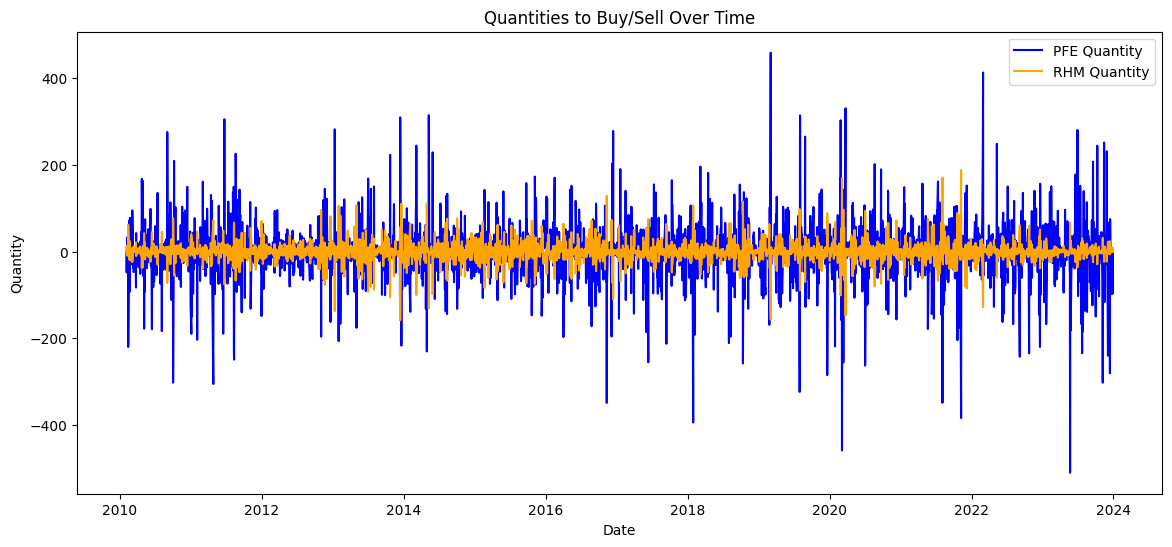

In [83]:
# Plot quantities
plt.figure(figsize=(14, 6))
plt.plot(mvp_weights_df.index, quantities_pfe, label="PFE Quantity", color="blue")
plt.plot(mvp_weights_df.index, quantities_rhm, label="RHM Quantity", color="orange")

plt.title("Quantities to Buy/Sell Over Time")
plt.xlabel("Date")
plt.ylabel("Quantity")
plt.legend()
plt

#### Compute Minimum Variance Portfolio Value over Time

In [84]:
# Create a Series to track portfolio value over time
portfolio_value_series = pd.Series(portfolio_values, index=mvp_weights_df.index)

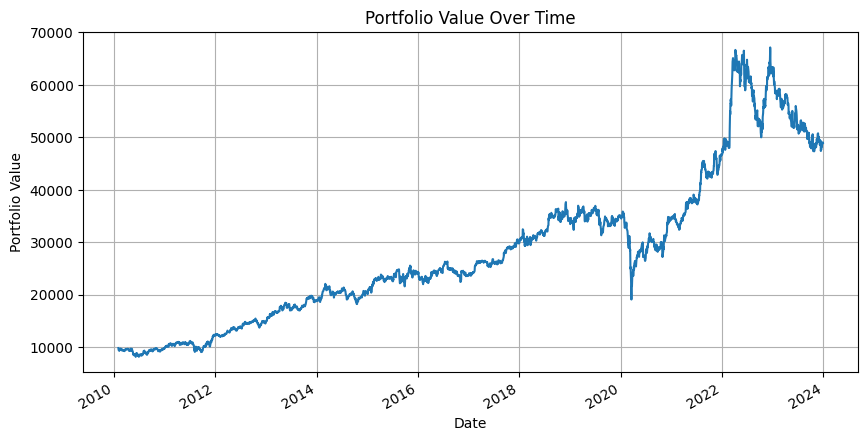

In [85]:
# Plot portfolio values over time
plt.figure(figsize=(10, 5))
portfolio_value_series.plot()
plt.title("Portfolio Value Over Time")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.grid(True)
plt.show()

The plot above displays the performance of the Minimum Variance Portfolio (MVP) from 2010 to 2024, assuming an initial investment of \$ 10,000. Over this period, the portfolio grows steadily reaching a peak value of approximately \$ 50,000 by early 2024. This trajectory reflects the effectiveness of a dynamic, risk-minimizing allocation strategy.

The portfolio experiences a noticeable dip in 2020, which aligns with the market turmoil triggered by the COVID-19 pandemic. This downturn is followed by a sharp recovery, with a significant surge in value observed around the beginning of 2022. This peak likely corresponds to geopolitical tensions, in particular the Russian invasion of Ukraine, which benefitted defense-related stocks like Rheinmetall.

Following this high point, the portfolio begins a gradual decline. This moderation may be attributed to the normalization of Pfizer's stock performance affter its pandemic-driven surge, as marktet conditions stabilize and investr sentiment adjusts.

Overall, the plot underscores the resilience and adaptability of the MVP strategy, which effectively navigates major market shocks while delivering substantial long-term growth thriugh optimal risk-adjusted asset allocation.

### Value at Risk (VaR) and Expected Shortfall (ES) Estimation

In order to assess the risk associated with the Minimum Variance Portfolio, particularly during periods of heightened market stress, we estimate two key risk metrics: Value at Risk (VaR) and Expected Shortfall (ES). These measures provide a quantitative framework for understanding potential lossess under adverse market conditions.

Value at Risk estimates the maximum expected loss over a given time horizon at a specified confidence level, 95% in our case.
VaR is useful for setting risk limits and capital reserves, but it does not provide any information about losses beyond this threshold.

To address this limitation, we also consider Expected Shortfall, which complements VaR by measuring the average loss that would occur in the worst 5% of cases. In other words, ES gives insight into the severity of losses in the tail of the distribution, making it a more informative metric in turbulent or extreme market scenatios.

Estimating VaR and ES allows us to evaluate how portfolio risk evolves over time, and how effectively the Minimum Variance Portfolio responds to major shocks, such as those experienced during COVID-19 pandemic and the Russia-Ukraine conflict.

#### Normal distributed Returns Assumption

A straightforward and widely used approach to estimate Value at Risk (VaR) and Expected Shortfall (ES) is to assume that asset returns follow a normal distribution. While this assumption may not fully capture the fat tails and skewness observed in real financial data, it provides a mathematically convenient framework and serves as a useful benchmark for risk estimation.

Under the normality assumption, both VaR and ES can be computed analytically using closed-form formulas that depend on the mean and standard deviation of portfolio returns. This method allows for fast and efficient computation, especially useful when evaluating risk on a daily basis.

The formulas used are:
- Value at Risk at confidence level α:
      VaR(α) = μ+σ⋅Φ^−1(α)

 where μ is the mean return, σ is the standard deviation, and Φ^−1(𝛼) is the inverse of the standard normal cumulative distribution function.

- Expected Shortfall at confidence level α:

      ES(α) = μ − σ⋅ ϕ(Φ^-1(α)) / (1 - α)

These formulas offer a simple yet insightful way to quantify downside risk, making it possible to track changes in portfolio risk over time and to quickly assess the impact of market shocks, assuming return distributions remain approximately normal.


In [86]:
# Compute daily VaR and ES at 95% confidence level
risk_df = compute_normal_var_es(mvp_weights_df, returns, cov_matrices)
risk_df.head()

,VaR,ES
2010-02-03,0.042483,0.048633
2010-02-04,0.055685,0.061933
2010-02-05,0.038098,0.045004
2010-02-08,0.032324,0.039293
2010-02-09,0.024851,0.031769


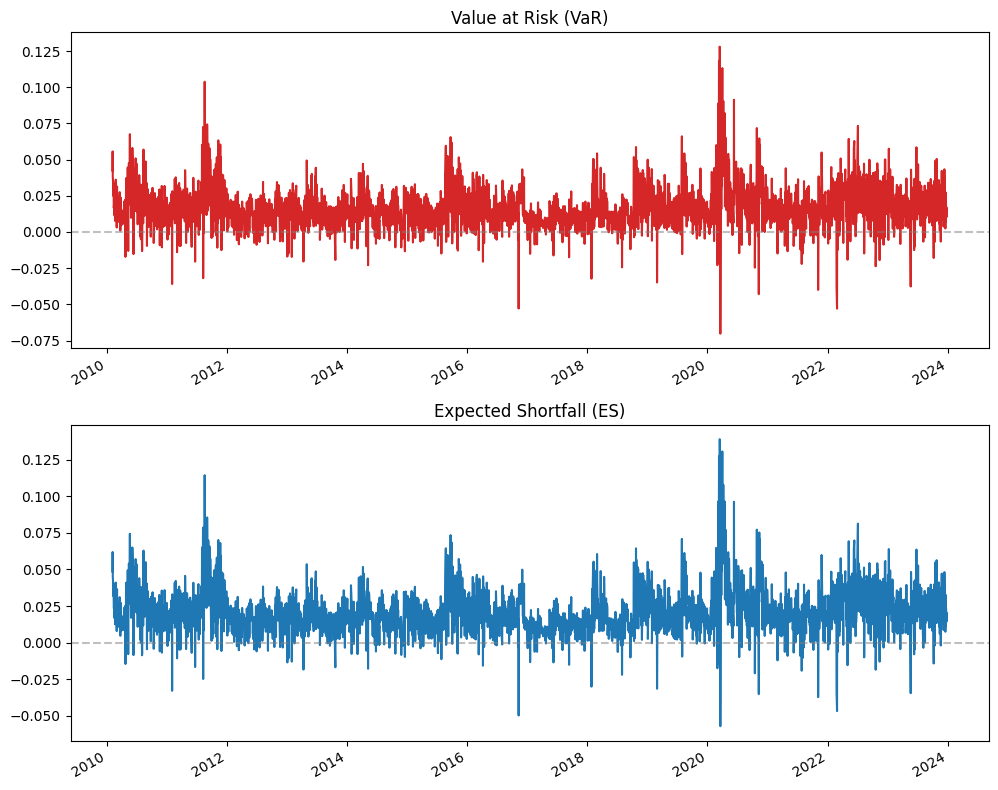

In [87]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 8))

# Plot VaR
risk_df["VaR"].plot(ax=axes[0], title="Value at Risk (VaR)", color='tab:red')
axes[0].axhline(0, linestyle="--", color="gray", alpha=0.5)

# Plot ES
risk_df["ES"].plot(ax=axes[1], title="Expected Shortfall (ES)")
axes[1].axhline(0, linestyle="--", color="gray", alpha=0.5)

plt.tight_layout()
plt.show()

### Stress Scenario

To enhance the model's adaptability during periods of extreme market stress, a stress-aware framework was introduced. The core idea is to improve the model's generalization under volatile conditions, such as sudden spikes or drops in asset prices, by giving greater importance to these periods during training and estimation. By assigning higher weights to high-volatility scenarios, the model becomes more sensitive to potential losses during such events, ultimatelly enabling more robust risk management and more resilient portfolio construction under adverse market conditions.

In [88]:
# Compute portfolio returns
common_dates = returns.index.intersection(mvp_weights_df.index)
returns = returns.loc[common_dates]
mvp_weights_df = mvp_weights_df.loc[common_dates]

portfolio_returns = []

for i in range(len(mvp_weights_df)):
  w = np.array(mvp_weights_df.iloc[i])
  r = np.array(returns.iloc[i])
  portfolio_return = np.dot(w, r)
  portfolio_returns.append(portfolio_return)

portfolio_returns = pd.Series(portfolio_returns, index=mvp_weights_df.index)

#### Historical Estimation


An alternative and widely used approach to estimating Value at Risk and Expected Shortfall is the historical method. Unlikr the parametric approach, which assumes that returns follow a normal distribution, this method is entirely data-driven and non-parametric. It relies on the empirical distribution of past returns, making no assumptions about the shape of the underlying distribution.

In practice, a rolling window of past returns is used to simulate how the portfolio might behave under historically observed market conditions. Within each window, returns are sorted, and the VaR is estimated as the empirical quantile corresponding to the chosen confidence level (e.g., the 5th percentile for a 95% confidence level). Thr ES is then computed as the average of all returns that fall below this threshold.

This approach offers several key advantages:
- No distributional assumptions: it naturally accounts for fat tails, skewness, and other non-normal characteristics often observed in real-world financial data.
- Scenario awareness: historical estimation directly incorporates actual extreme events from the past, providing more realistic risk estimates in turbulent periods.



In [89]:
window_sizes = [10, 20, 30, 40, 60]
param_metrics = var_es_param_grid_search(portfolio_returns, window_sizes, [0.002], [2], [2], "historical")
param_metrics

Current window:  10
Current window:  20
Current window:  30
Current window:  40
Current window:  60


,window,VaR Violation Rate,Actual ES,Predicted ES
0,10,12.230635,0.016516,0.016906
1,20,9.141355,0.018962,0.021321
2,30,7.967194,0.020437,0.020994
3,40,6.991774,0.021781,0.023008
4,60,6.146572,0.023480,0.024007


In [90]:
# Find best parameters
best_params_historical = find_best_params(param_metrics, "historical")
best_params_historical

[{'window': np.float64(60.0)}]

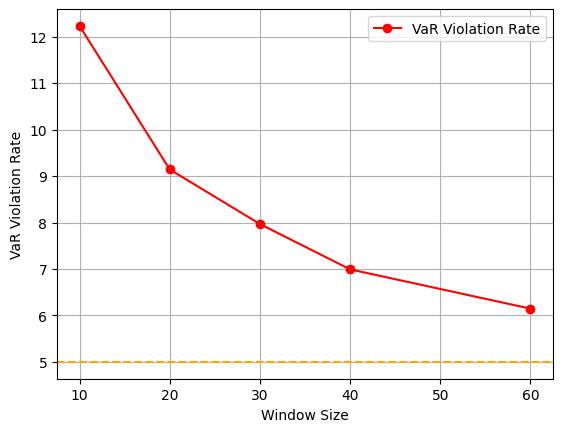

In [91]:
# Plot results for tested paramters
plt.plot(param_metrics["window"], param_metrics["VaR Violation Rate"], label="VaR Violation Rate", marker='o', color='red')
plt.axhline(5, linestyle="--", color="orange", alpha=1)
plt.xlabel("Window Size")
plt.ylabel("VaR Violation Rate")
plt.grid(True)
plt.legend()
plt.show()

The only parameter in the historical risk estimation model is the size of the rolling window. This parameter plays a crucial role in determining the quality of the risk estimates. A window that is too short may capture only short-term fluctuations or noise, leading to unstable and unreliable results. Conversely, a window that is too long may smooth over recent market dynamics, failing to adapt to changing conditions and potentially underestimating risk.

A parameter grid search indicates that performance tends to improve as the window size increases, as a larger sample provides more robust statistical estimates. However, there is a trade-off: using an excessively large window can be impractical, especially when the available test data is limited. In such cases, a large window may reduce the model’s responsiveness and diminish its ability to capture recent market stress, particularly in shorter evaluation periods.

Finding the right balance is therefore essential—ensuring that the window is large enough to provide meaningful estimates without sacrificing the model's adaptability or the integrity of the test set.

In [92]:
window = int(best_params_historical[0]["window"])
VaR_series_historical, ES_series_historical = historical_var_es(portfolio_returns, window=window)

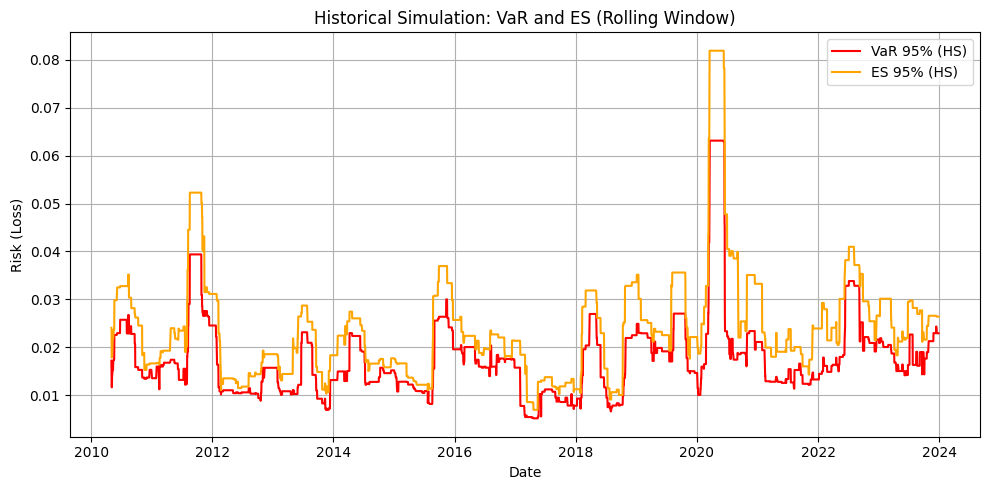

In [93]:
plt.figure(figsize=(10, 5))
plt.plot(VaR_series_historical, label="VaR 95% (HS)", color='red')
plt.plot(ES_series_historical, label="ES 95% (HS)", color='orange')
plt.title("Historical Simulation: VaR and ES (Rolling Window)")
plt.xlabel("Date")
plt.ylabel("Risk (Loss)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The plot above illustrates the evolution of Value at Risk (VaR) and Expected Shortfall (ES) over the period 2010–2023, as estimated using the historical simulation approach. These risk measures represent the potential losses of the Minimum Variance Portfolio under normal and extreme market conditions, respectively.

The results suggest that the model effectively captures periods of elevated market stress. In particular, the most prominent peaks in both VaR and ES align with two major global events: the COVID-19 pandemic in 2020 and the onset of the Russian invasion of Ukraine in early 2022. These spikes reflect the sudden surge in market volatility during these periods, indicating heightened potential for portfolio losses.

Overall, the historical method demonstrates good responsiveness to real-world shocks, as it does not rely on strong distributional assumptions and instead directly incorporates observed market behavior. This makes it a valuable tool for estimating portfolio risk in environments characterized by abrupt changes and non-normal return distributions.

#### Stress Amplification

The stressed historical method builds on the standard historical simulation approach by introducing a mechanism to emphasize periods of elevated market volatility. While the traditional historical method treats all past observations equally, the stressed approach selectively amplifies the impact of high-volatility days within the rolling window.

This is achieved through several steps:
- Identifying high-volatility periods using a secondary rolling volatility measure (e.g., 20-days rolling standard deviation).
- Applying a multiplier to returns during these volatile periods, artificially increasing their influence on the distribution of simulated losses.
- Recomputing VaR and ES from this adjusted return distribution, placing more weight on extreme losses.

This model does not require distributional assumptions, and has better sensitivity to market stress: by up-weighting returns from turbulent periods, the model accurately reflects the risk posed by sudden market shocks, something the standard historical method might understate due to the dilution by calmer periods.


In [94]:
window_sizes = [10, 20, 30, 40, 60]
stress_thresholds = [0.001, 0.002, 0.005, 0.01]
stress_multipliers = [1, 1.5, 2, 2.5, 3]
param_metrics = var_es_param_grid_search(portfolio_returns, window_sizes, stress_thresholds, stress_multipliers, [2], "stress")

param_metrics

Current window:  10
Current window:  20
Current window:  30
Current window:  40
Current window:  60


,window,stress_threshold,stress_multiplier,VaR Violation Rate,Actual ES,Predicted ES
0,10,0.001,1.0,12.230635,0.016516,0.016906
1,10,0.001,1.5,12.230635,0.016516,0.016906
2,10,0.001,2.0,12.230635,0.016516,0.016906
3,10,0.001,2.5,12.230635,0.016516,0.016906
4,10,0.001,3.0,12.230635,0.016516,0.016906
...,...,...,...,...,...,...
95,60,0.010,1.0,6.146572,0.023480,0.024007
96,60,0.010,1.5,4.462175,0.024087,0.030461
97,60,0.010,2.0,3.634752,0.023673,0.037917
98,60,0.010,2.5,3.132388,0.022518,0.045723


In [95]:
# Find best parameters
best_params_stress = find_best_params(param_metrics, "stress")
best_params_stress

[{'window': np.float64(60.0),
  'stress_threshold': np.float64(0.01),
  'stress_multiplier': np.float64(3.0)}]

This model is governed by three key parameters, each playing a crucial role in shaping how the Value at Risk (VaR) and Expected Shortfall (ES) respond to historical and stressed market conditions:

- Window Size: Defines the length of the rolling window used to estimate VaR and ES. A larger window incorporates more historical data, improving statistical stability, while a smaller window increases sensitivity to recent market movements.

- Stress Threshold: Determines the volatility level above which a period is considered "stressed." Returns during periods exceeding this threshold are treated differently to emphasize turbulent conditions.

- Stress Multiplier: Amplifies the impact of returns observed during stressed periods. The purpose of this parameter is to increase the model’s responsiveness to extreme events, making risk estimates more conservative when volatility is high.

A parametric grid search over these parameters revealed two key insights:

- The optimal stress threshold is relatively low, meaning the model flags only the most extreme volatility episodes as stress events. This helps avoid overreacting to moderate market fluctuations.

- The best-performing stress multiplier is found to be 3, indicating that heavily upweighting losses during these identified stress periods significantly improves the model’s ability to anticipate future downside risk.

Together, these results suggest that focusing on only the most severe past events and amplifying their influence leads to more robust risk estimates. This makes the model especially effective at adapting to sudden shocks—such as pandemics or geopolitical crises—without becoming overly reactive to ordinary market noise.

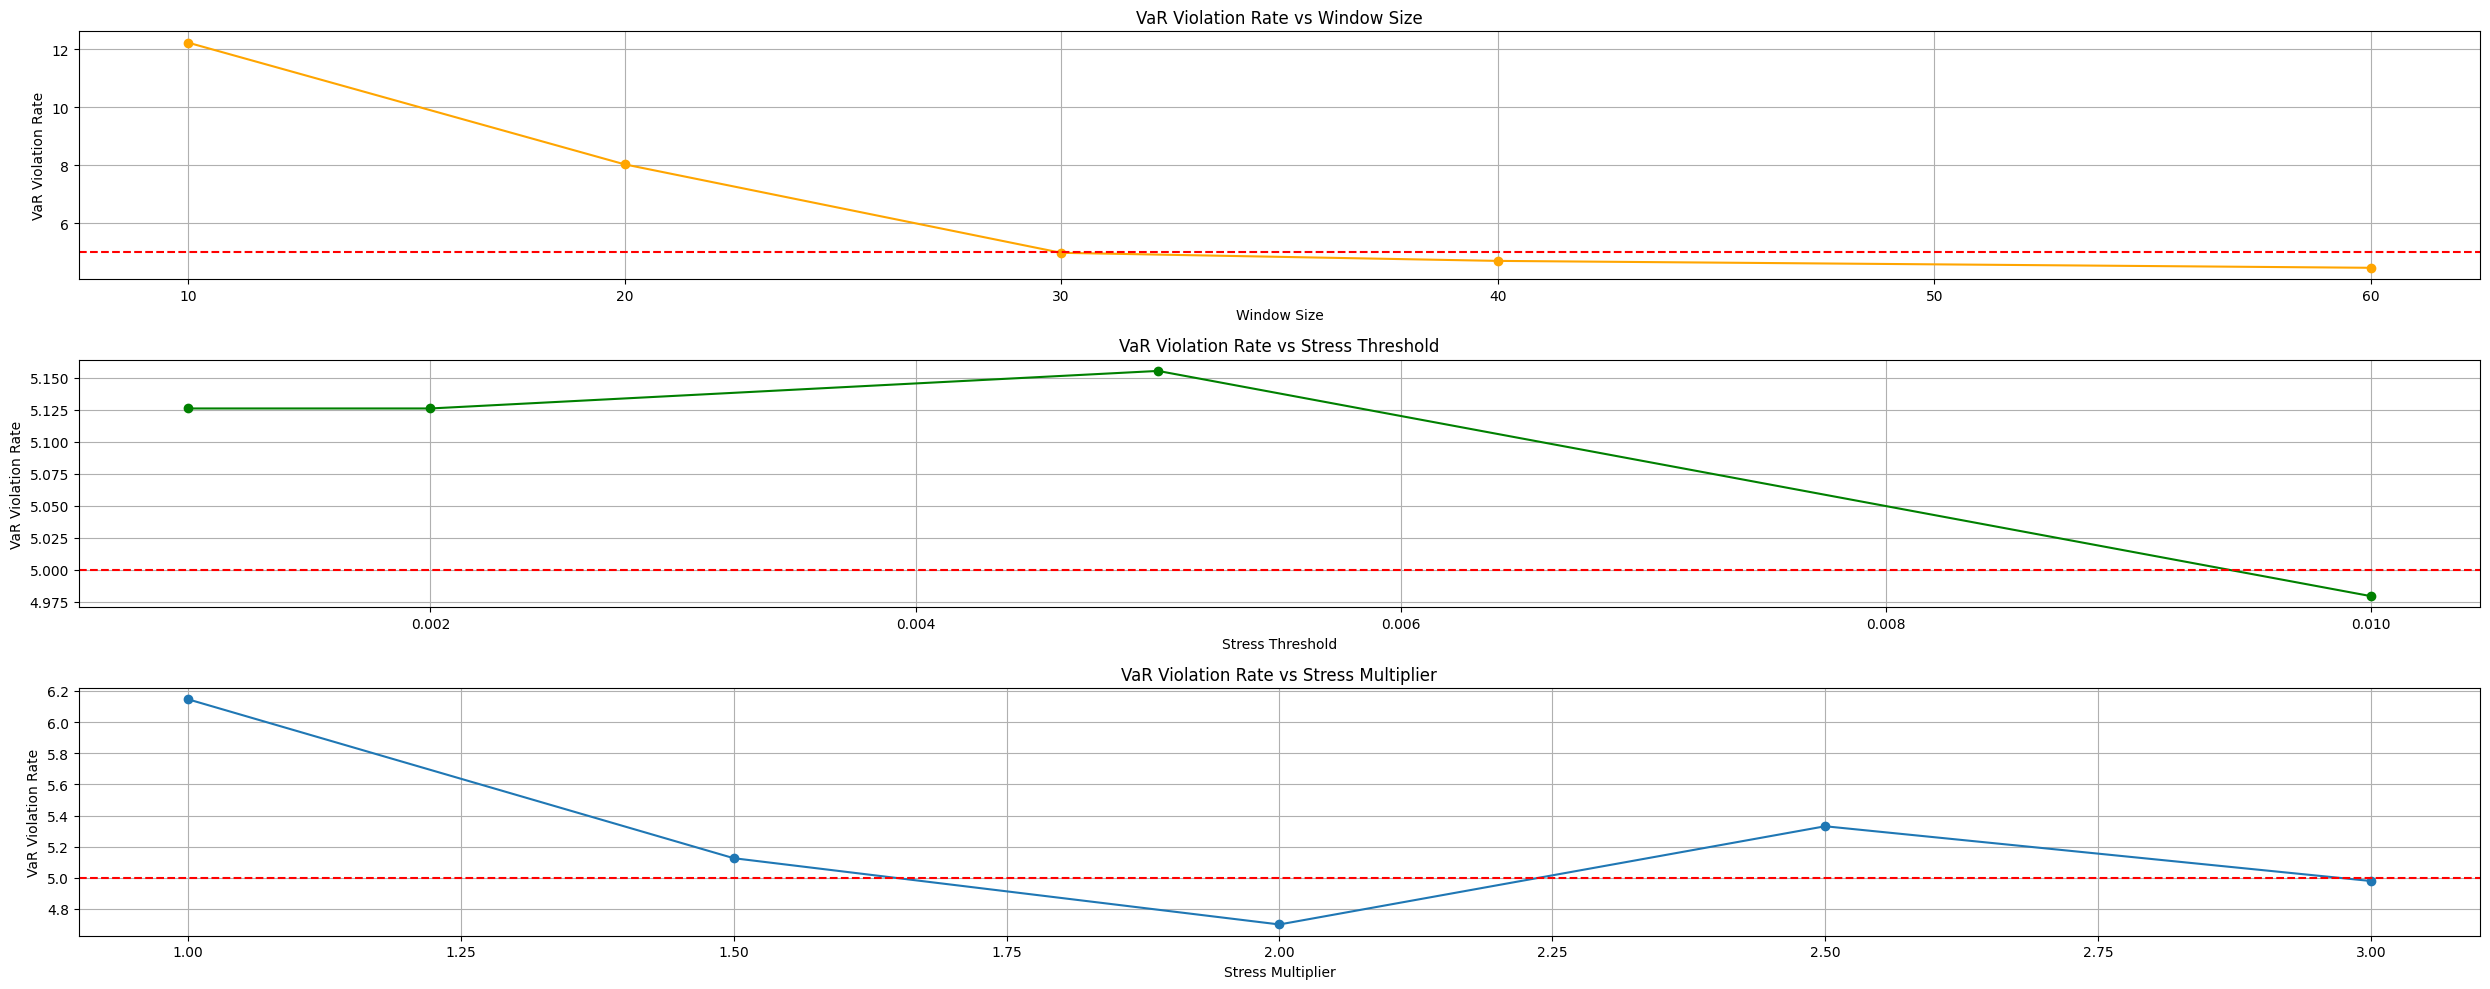

In [96]:
target = 5

# window vs VaR
window_sizes = sorted(param_metrics["window"].unique())
violation_rate_on_window = []

for window in window_sizes:
  subset = param_metrics[param_metrics["window"] == window]
  id = (subset['VaR Violation Rate'] - target).abs().idxmin()
  violation_rate_on_window.append(subset.loc[id, "VaR Violation Rate"])

# VaR vs stress_threshold
stress_thresholds = sorted(param_metrics["stress_threshold"].unique())
violation_rate_on_threshold = []

for threshold in stress_thresholds:
  subset = param_metrics[param_metrics["stress_threshold"] == threshold]
  id = (subset['VaR Violation Rate'] - target).abs().idxmin()
  violation_rate_on_threshold.append(subset.loc[id, "VaR Violation Rate"])

#VaR vs stress_multiplier
stress_multipliers = sorted(param_metrics["stress_multiplier"].unique())
violation_rate_on_multiplier = []

for multiplier in stress_multipliers:
  subset = param_metrics[param_metrics["stress_multiplier"] == multiplier]
  id = (subset['VaR Violation Rate'] - target).abs().idxmin()
  violation_rate_on_multiplier.append(subset.loc[id, "VaR Violation Rate"])

# Plot
fig, axs = plt.subplots(3, 1, figsize=(25, 10))

# plot 1
axs[0].plot(window_sizes, violation_rate_on_window, marker='o', color='orange')
axs[0].axhline(target, linestyle="--", color="red", alpha=1)
axs[0].set_title("VaR Violation Rate vs Window Size")
axs[0].set_xlabel("Window Size")
axs[0].set_ylabel("VaR Violation Rate")
axs[0].grid(True)

# plot 2
axs[1].plot(stress_thresholds, violation_rate_on_threshold, marker='o', color='green')
axs[1].axhline(target, linestyle="--", color="red", alpha=1)
axs[1].set_title("VaR Violation Rate vs Stress Threshold")
axs[1].set_xlabel("Stress Threshold")
axs[1].set_ylabel("VaR Violation Rate")
axs[1].grid(True)

# plot 3
axs[2].plot(stress_multipliers, violation_rate_on_multiplier, marker='o')
axs[2].axhline(target, linestyle="--", color="red", alpha=1)
axs[2].set_title("VaR Violation Rate vs Stress Multiplier")
axs[2].set_xlabel("Stress Multiplier")
axs[2].set_ylabel("VaR Violation Rate")
axs[2].grid(True)

plt.tight_layout()


In [97]:
window = int(best_params_stress[0]["window"])
stress_threshold = best_params_stress[0]["stress_threshold"]
stress_multiplier = best_params_stress[0]["stress_multiplier"]
VaR_series_stress, ES_series_stress = stress_var_es(portfolio_returns, window, stress_threshold, stress_multiplier)

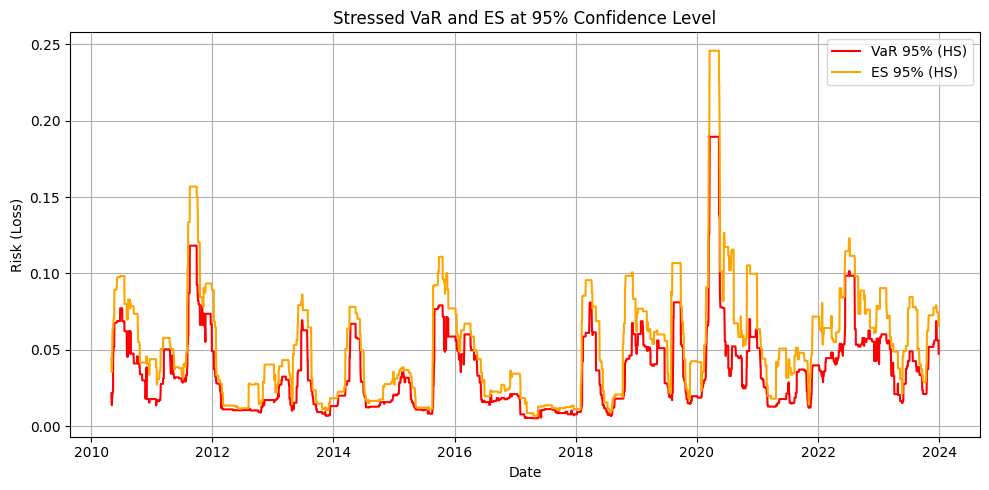

In [98]:
plt.figure(figsize=(10, 5))
plt.plot(VaR_series_stress, label="VaR 95% (HS)", color='red')
plt.plot(ES_series_stress, label="ES 95% (HS)", color='orange')
plt.title("Stressed VaR and ES at 95% Confidence Level")
plt.xlabel("Date")
plt.ylabel("Risk (Loss)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The plot above shows the evolution of Value at Risk and Expected Shortfall estimates over time using the stress-amplified model. The overall shaoe of the distribution closely resembles that produces by the simple historical method, indicating that this approach successfully captures both high-volatility and stable periods in the market.

However, a key difference lies in the magnitude of the estimated losses. During periods identified as stressed, this model produces significantly higher VaR and ES values. This behavior is expected: by amplifying returns during volatile episodes, the model becomes more conservative, placing grater emphasis on the tail risk associated with rare but sever events.

This shift in scale demonstrates the model's increased risk sensitivity and its ability to prioritize capital preservation under adverse conditions. As a result, it offers a more robust framework for decision-making during periods of heightened uncerainty, making it better suited for real-world portfolio risl management under stress scenarios.

#### Stress Amplification with Z-Score

The z-threshold stress model introduces a more adaptive and statistically robust approach to identifying periods of market stress by dynamically adjusting for volatility shocks. Unlike simpler stress models that rely on a fixed threshold to flag stress periods, this method leverages z-scores, a standardized measure of volatility deviation, to determine when the market is exhibiting truly abnormal behavior.

At the core of the model is the rolling computation of volatility within a specified time window. For each day in the window, the model calculates the mean and standard deviation of volatility, then computes the z-score of each day's volatility. The z-score quantifies how many standard deviations a particular volatility observation lies from the mean, allowing the model to detect relative anomaliies instead of absolute values. This makes the approach significantly more context-sensitive: in a generally volatile market, what would be considered "stressful" is different than in a calm one.

When the z-score exceeds a predefined z-threshold, the model identifies the corresponding return as belonging to a high-stress period. During these periods, the model amplifies the impact of the returns by applying a stress multiplier, effectively increasing the weight of extreme losses in the distribution. This targeted amplification ensures that:
- Short-lived or mild fluctuations are not mistakenly treated as structural risk;
- Only statistically exceptional volatility events are emphasized.

After adjusting the returns, the model constructs an empirical distribution and calculates VaR and ES based on the stressed return series. This approach leads to more cautious risk estimates during abnormal periods while maintaining realistic expectations in calmer conditions.

Overall, the z-threshold stress model offers a more intelligent and adaptive framework for risk estimation, capable of capturing tail events without overfitting to transient market noise.

In [99]:
window_sizes = [10, 20, 30, 40, 60]
stress_multipliers = [1, 1.5, 2, 2.5, 3]
z_thresholds = [1, 2, 3]

param_metrics = var_es_param_grid_search(portfolio_returns, window_sizes, [0.002], stress_multipliers, z_thresholds, "z_threshold")
param_metrics

Current window:  10
Current window:  20
Current window:  30
Current window:  40
Current window:  60


,window,stress_multiplier,z_threshold,VaR Violation Rate,Actual ES,Predicted ES
0,10,1.0,1,12.230635,0.016516,0.016906
1,10,1.0,2,12.230635,0.016516,0.016906
2,10,1.0,3,12.230635,0.016516,0.016906
3,10,1.5,1,12.230635,0.016516,0.016906
4,10,1.5,2,12.230635,0.016516,0.016906
...,...,...,...,...,...,...
70,60,2.5,2,6.146572,0.023480,0.024007
71,60,2.5,3,6.146572,0.023480,0.024007
72,60,3.0,1,6.146572,0.023480,0.024007
73,60,3.0,2,6.146572,0.023480,0.024007


In [100]:
# Find best params
best_params_z_threshold = find_best_params(param_metrics, "z_threshold")
best_params_z_threshold

[{'window': np.float64(60.0),
  'stress_multiplier': np.float64(3.0),
  'z_threshold': np.float64(3.0)}]

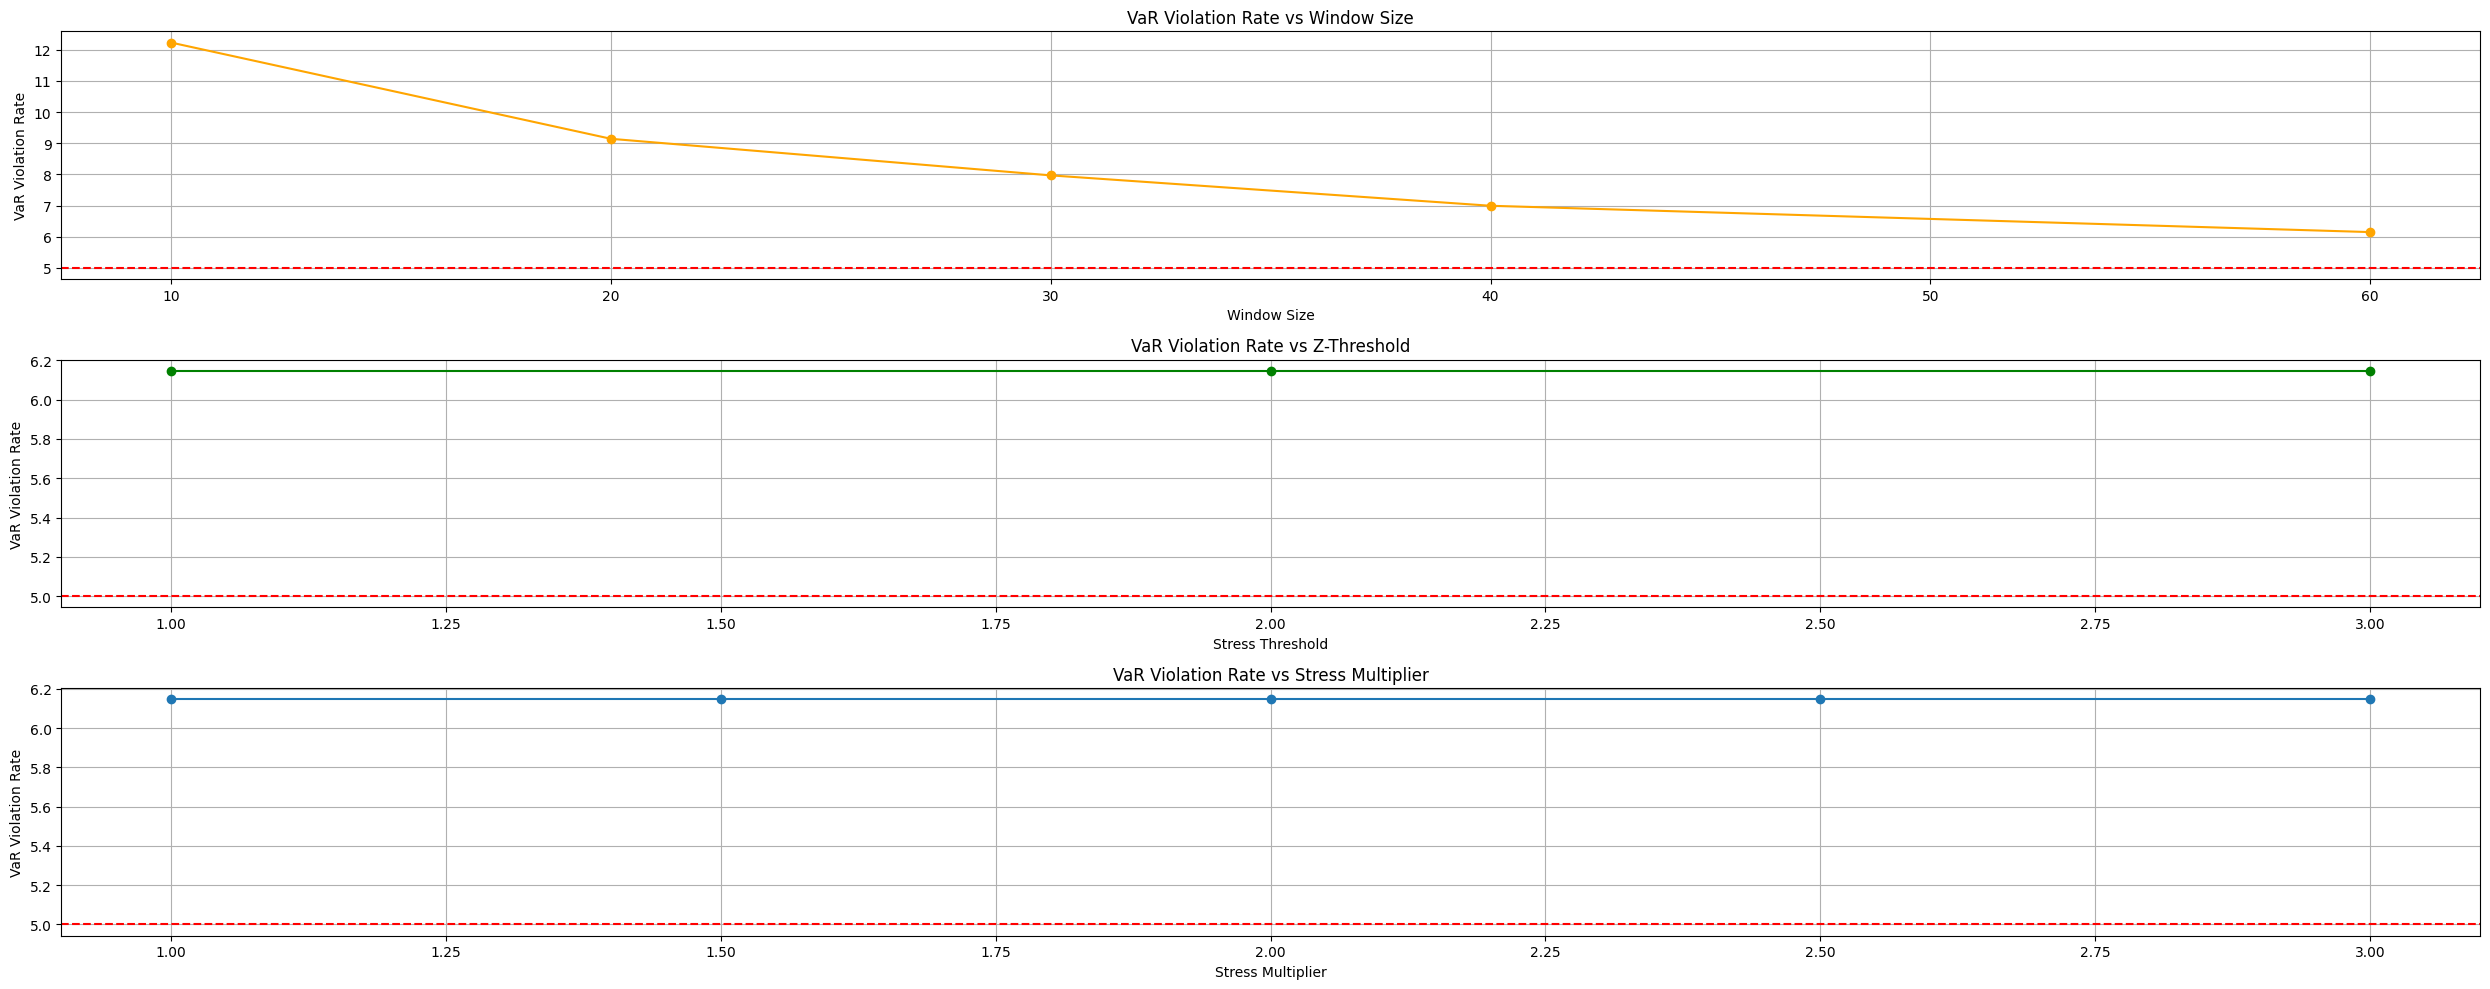

In [101]:
target = 5

# window vs VaR
window_sizes = sorted(param_metrics["window"].unique())
violation_rate_on_window = []

for window in window_sizes:
  subset = param_metrics[param_metrics["window"] == window]
  id = (subset['VaR Violation Rate'] - target).abs().idxmin()
  violation_rate_on_window.append(subset.loc[id, "VaR Violation Rate"])

# VaR vs z-threshold
z_thresholds = sorted(param_metrics["z_threshold"].unique())
violation_rate_on_threshold = []

for threshold in z_thresholds:
  subset = param_metrics[param_metrics["z_threshold"] == threshold]
  id = (subset['VaR Violation Rate'] - target).abs().idxmin()
  violation_rate_on_threshold.append(subset.loc[id, "VaR Violation Rate"])

#VaR vs stress_multiplier
stress_multipliers = sorted(param_metrics["stress_multiplier"].unique())
violation_rate_on_multiplier = []

for multiplier in stress_multipliers:
  subset = param_metrics[param_metrics["stress_multiplier"] == multiplier]
  id = (subset['VaR Violation Rate'] - target).abs().idxmin()
  violation_rate_on_multiplier.append(subset.loc[id, "VaR Violation Rate"])

# Plot
fig, axs = plt.subplots(3, 1, figsize=(25, 10))

# plot 1
axs[0].plot(window_sizes, violation_rate_on_window, marker='o', color='orange')
axs[0].axhline(target, linestyle="--", color="red", alpha=1)
axs[0].set_title("VaR Violation Rate vs Window Size")
axs[0].set_xlabel("Window Size")
axs[0].set_ylabel("VaR Violation Rate")
axs[0].grid(True)

# plot 2
axs[1].plot(z_thresholds, violation_rate_on_threshold, marker='o', color='green')
axs[1].axhline(target, linestyle="--", color="red", alpha=1)
axs[1].set_title("VaR Violation Rate vs Z-Threshold")
axs[1].set_xlabel("Stress Threshold")
axs[1].set_ylabel("VaR Violation Rate")
axs[1].grid(True)

# plot 3
axs[2].plot(stress_multipliers, violation_rate_on_multiplier, marker='o')
axs[2].axhline(target, linestyle="--", color="red", alpha=1)
axs[2].set_title("VaR Violation Rate vs Stress Multiplier")
axs[2].set_xlabel("Stress Multiplier")
axs[2].set_ylabel("VaR Violation Rate")
axs[2].grid(True)

plt.tight_layout()

In [102]:
window = int(best_params_z_threshold[0]["window"])
stress_multiplier = best_params_z_threshold[0]["stress_multiplier"]
z_threshold = best_params_z_threshold[0]["z_threshold"]
VaR_series_stress_z_threshold, ES_series_stress_z_threshold = stressed_var_es_z_threshold(portfolio_returns, window, stress_multiplier, z_threshold)

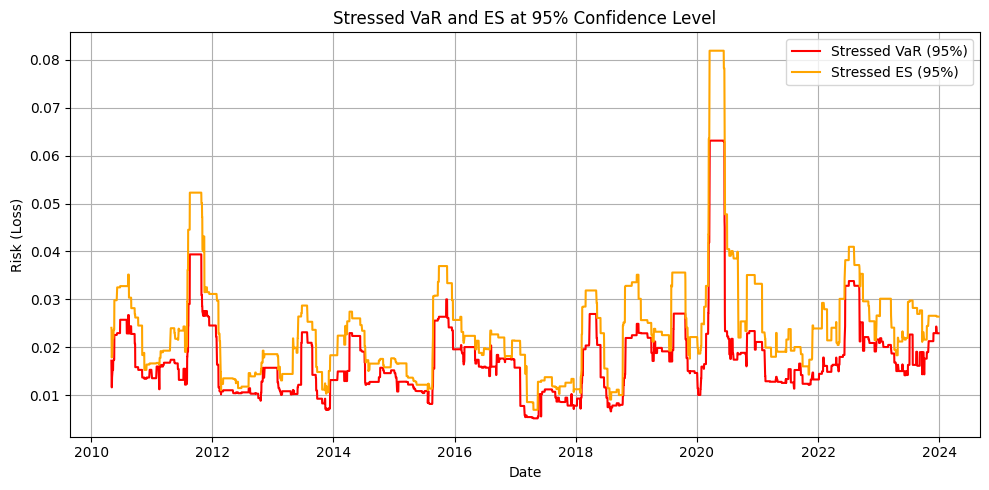

In [103]:
plt.figure(figsize=(10, 5))
plt.plot(VaR_series_stress_z_threshold, label="Stressed VaR (95%)", color='red')
plt.plot(ES_series_stress_z_threshold, label="Stressed ES (95%)", color='orange')
plt.title("Stressed VaR and ES at 95% Confidence Level")
plt.xlabel("Date")
plt.ylabel("Risk (Loss)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### Long Short Term Memory (LSTM)

As a final step in developing a robust risk estimation framework, we explore the use of Long Short-Term Memory (LSTM) networks, a type of recurrent neural network (RNN) well-suited for capturing complex temporal dependencies in sequential data. Unlike the previous models, which rely on statistical assumptions or rule-based mechanisms to define market stress, LSTMs can learn patterns directly from data, making them highly flexible and potentially more powerful in identifying risk under volatile and non-linear market conditions.

The motivation behind using LSTMs stems from the limitations of traditional approaches:
- Normal distribution-based methods fail to account for heavy tails and volatility clustering in real financial returns.
- Historical methods treat each observation with equal weight, lacking adaptability to new regimes.
- Stress-amplified models, while more sensitive to turbulent conditions, still depend on hand-crafted rules to define what constitutes stress.

In contrast, an LSTM can learn to recognize sequences of market behavior, such as rising volatility, momentum reversals, or sharp drawdowns, and use these patterns to predict future Value at Risk and Epected Shortfall. By feeding the netwoel rolling window of returns and volatilities, the model can dynamically infer risk levels without rigid assumptions.

This deep learning approach offers three key advantages:
- Adaptability: it learns from historical data and adjusts to evolving market structures.
- Non-linearity: it captures complex relationships that are difficult to model explicitly.
- Temporal awareness: it considers the order and dynamics of events, rather than treating data points in isolation.

In [104]:
# Estimate realized volatility
window_vol = 20
realized_vol = portfolio_returns.rolling(window_vol).std().dropna()

In [105]:
# Prepare LSTM Inpuut Sequences
loockback = 30 # Number of days LSTM uses as input

X, y = [], []
vol_values = realized_vol.values

for i in range(loockback, len(vol_values)):
    X.append(vol_values[i-loockback:i])
    y.append(vol_values[i])

X = np.array(X)
y = np.array(y)

# Reshape for LSTM input: [samples, time_steps, features]
X = X.reshape((X.shape[0], X.shape[1], 1))

In [106]:
# Train the LSTM Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

model = Sequential([
    LSTM(50, activation='relu', input_shape=(loockback, 1)),
    Dense(1)
])

model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model.fit(X, y, epochs=20, batch_size=16, verbose=1)

Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


213/213 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 2.1856e-05
Epoch 2/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 4.4990e-06
Epoch 3/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 3.7836e-06
Epoch 4/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 2.9481e-06
Epoch 5/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 2.1685e-06
Epoch 6/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 2.0870e-06
Epoch 7/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 1.8753e-06
Epoch 8/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 1.4686e-06
Epoch 9/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 1.6435e-06
Epoch 10/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 1.6066e-06
Epoch 11/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1.7730e-06
Epoch 12/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 2.0153e-06
Epoch 13/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 1.3902e-06
Epoch 14/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 1.4560e-0

In [107]:
# Use LSTM Forecasts to Compute VaR and ES
from scipy.stats import norm
import pandas as pd

def lstm_var_es(portfolio_returns, lstm_model, lookback, confidence_level=0.95):
    z = norm.ppf(1 - confidence_level)
    phi_z = norm.pdf(z)

    VaRs, ESs, dates = [], [], []

    # Prepare rolling inputs
    for i in range(lookback + 20, len(portfolio_returns)):  # +20 due to vol window
        returns_window = portfolio_returns.iloc[i-lookback-20:i]
        vol_series = returns_window.rolling(20).std().dropna()

        # Ensure shape consistency
        if len(vol_series) < lookback:
            continue

        # Prepare LSTM input
        x_input = vol_series.values[-lookback:].reshape(1, lookback, 1)

        # Forecast next-day volatility
        forecast_vol = lstm_model.predict(x_input, verbose=0)[0][0]

        # Compute VaR and ES
        VaR = -z * forecast_vol
        ES = forecast_vol * phi_z / (1 - confidence_level)

        date = portfolio_returns.index[i]
        VaRs.append(VaR)
        ESs.append(ES)
        dates.append(date)

    return pd.Series(VaRs, index=dates), pd.Series(ESs, index=dates)

VaR_series_lstm, ES_series_lstm = lstm_var_es(portfolio_returns, model, loockback)


### Models Validation and Comparison

To determine which model offers the most reliable risk forecasts, and evaluate the effectiveness of each approach individually, we assess their performance on historical data using two key metrics:

- VaR Violation Rate: This represents the percentage of days in which the actual loss exceeded the predicted Value at Risk (VaR). Given a confidence level of 95%, the ideal violation rate should be close the 5%. A higher violation rate suggests that the model underestimates risk, failing to anticipate significant losses. Conversely, a lower rate indicates that the model is overly conservative, potentially limiting capital efficiency by predicting risk that rarely materializes.

- Actual Expected Shortfall (ES): This measures the average loss on days when VaR was breached; in other words, how severe losses are when the model fails to contain them. A well-performing model should yield an actual ES that closely matches the predicted ES, indicating that it not only identifies risky periods but also accurately estimates the magnitude of potential losses in extreme conditions.

Together, these two metrics offer a balanced view: VaR Violation Rate assesses the frequency of unexpected losses, while Actual ES captures their severity, enabling a comprehensive comparison of each model's predictive power and robustness under stress.

In [110]:
# Collect model evaluation results
model_results = [
    {
        "Model": "Normal Distribution",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, risk_df['VaR'], risk_df['ES'])[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, risk_df['VaR'], risk_df['ES'])[1]
    },
    {
        "Model": "Historical",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_historical, ES_series_historical)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_historical, ES_series_historical)[1]
    },
    {
        "Model": "Stress Amplification",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_stress, ES_series_stress)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_stress, ES_series_stress)[1]
    },
    {
        "Model": "Stress Amplification (Z-Score)",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_stress_z_threshold, ES_series_stress_z_threshold)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_stress_z_threshold, ES_series_stress_z_threshold)[1]
    },
    {
        "Model": "LSTM",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_lstm, ES_series_lstm)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_lstm, ES_series_lstm)[1]
    }
]

# Create and format results DataFrame
results_df = pd.DataFrame(model_results)
results_df["VaR Violation Rate (%)"] = results_df["VaR Violation Rate (%)"].round(2)
results_df["Actual ES"] = results_df["Actual ES"].round(4)

# Display the the table
results_df

,Model,VaR Violation Rate (%),Actual ES
0,Normal Distribution,0.00,NaN
1,Historical,6.15,0.0235
2,Stress Amplification,2.78,0.0205
3,Stress Amplification (Z-Score),6.15,0.0235
4,LSTM,4.24,0.0271


The table above compares the performance of each risk model using two key metrics: the VaR Violation Rate and the Actual Expected Shortfall. The ideal model should have a violation rate close to the confidence level (5%) and an Actual ES value close to the predicted one.

The normal distribution model shows no violations, highlighting its overly conservative nature and poor calibration. The historical model slightly underestimates risk, while stress amplification improves caution but at the cost of being too conservative.
Interestingly, the z-score stress model behaves similarly to the simple historical method, possibly indicating parameter sensitivity.
The LSTM model offers the best violation rate match, though it tends to underestimate the severity of rare losses when they do occur.

## Model Evaluation

After calibrating the models and selecting their optimal parameters on historical data, it is crucial to assess their ability to generalize and perform under truly stressed, unseen conditions. To this end, the period spanning 2024–2025 was selected as a dedicated test set. This timeframe offers a realistic and challenging evaluation environment, particularly due to the significant market shocks that occurred in 2025. These events provide a meaningful context to examine how well each model adapts to heightened volatility and unexpected financial stress, shedding light on their robustness and reliability in real-world risk forecasting.

### Compute Dynamic Covariance Matrix

In [111]:
window = 20

last_training_returns = returns.iloc[len(returns) - window:]

test_returns = pd.concat([test_pfe["Close"].pct_change(), test_rhm["Close"].pct_change()], axis=1)
test_returns.columns = ['pfe', 'rhm']

# Eliminate NaN
test_returns = test_returns.dropna()

test_returns.head()

,pfe,rhm
Date,,
2024-01-03,0.000000,-0.007353
2024-01-04,-0.021527,0.027273
2024-01-05,0.013063,0.000000
2024-01-08,0.003733,0.007538
2024-01-09,-0.006085,-0.007482


In [112]:
test_returns = pd.concat([last_training_returns, test_returns])
test_returns.head()

,pfe,rhm
2023-11-30,0.012965,0.002907
2023-12-01,-0.051198,0.020652
2023-12-04,0.012798,0.006035
2023-12-05,-0.006489,0.000353
2023-12-06,-0.010313,-0.003527


In [113]:
rolling_cov = compute_cov_matrices(test_returns, window)

### Estimating Minimum Variance Portfolio (MVP)

In [114]:
mvp_weights_df = compute_mvp_weights(rolling_cov)
mvp_weights_df.head()

,w_pfe,w_rhm
2024-01-03,0.176327,0.823673
2024-01-04,0.185445,0.814555
2024-01-05,0.214663,0.785337
2024-01-08,0.217557,0.782443
2024-01-09,0.218904,0.781096


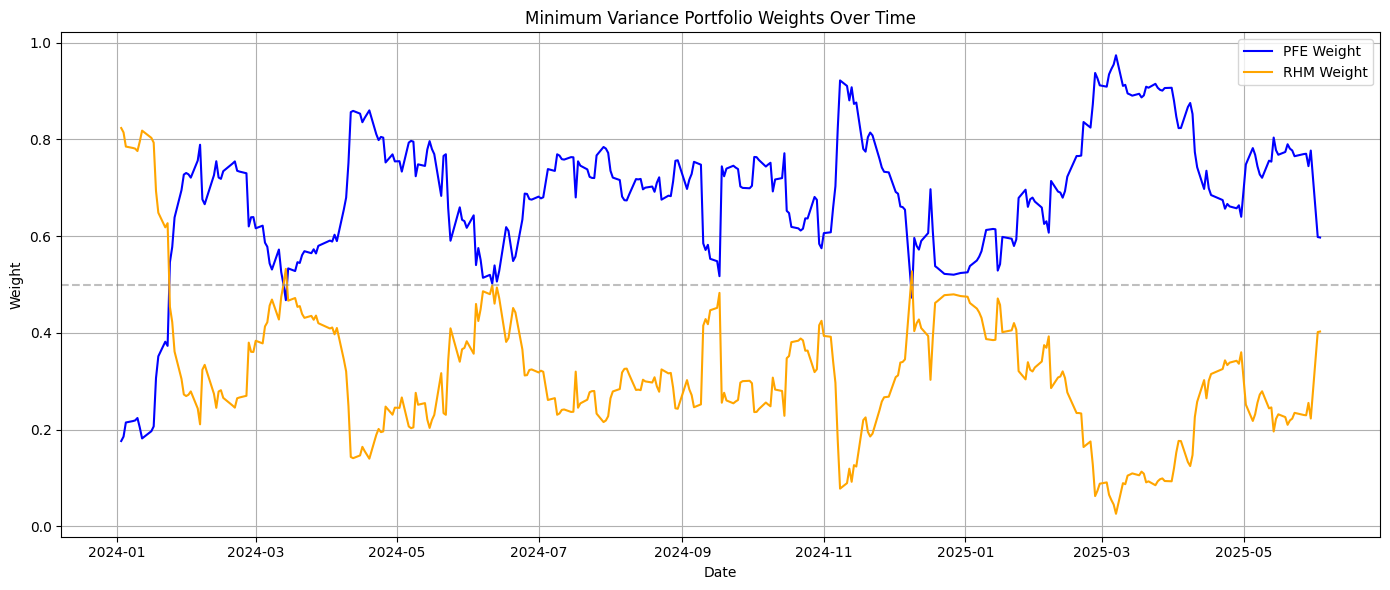

In [115]:
# Plot the weights
plt.figure(figsize=(14, 6))
plt.plot(mvp_weights_df.index, mvp_weights_df["w_pfe"], label="PFE Weight", color="blue")
plt.plot(mvp_weights_df.index, mvp_weights_df["w_rhm"], label="RHM Weight", color="orange")
plt.axhline(0.5, linestyle="--", color="gray", alpha=0.5)

plt.title("Minimum Variance Portfolio Weights Over Time")
plt.xlabel("Date")
plt.ylabel("Weight")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The allocation of capital between the two assets during the test period mirrors the trend observed in the training set: the majority of the investment is directed toward Pfizer, with only a small portion allocated to Rheinmetall. This pattern likely reflects the elevated volatility exhibited by Rheinmetall since 2022, largely driven by geopolitical tensions and defense-related market dynamics. As a result, the model treats Rheinmetall as a higher-risk asset. In contrast, Pfizer demonstrates greater price stability, making it a more attractive option for a minimum variance strategy focused on risk reduction.

In [116]:
capital = 10000

portfolio_values, quantities_pfe, quantities_rhm = compute_mvp_value_quantities(mvp_weights_df, test_returns, capital, test_pfe, test_rhm)

/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1345: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.11/dist-packages/matplotlib/pyplot.py'>

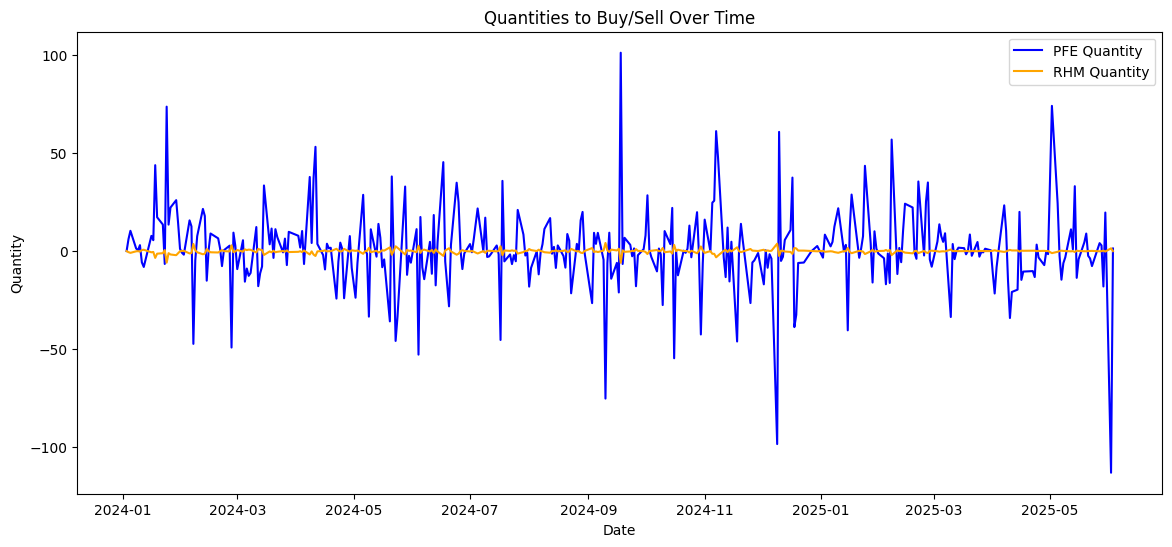

In [117]:
# Plot quantities
plt.figure(figsize=(14, 6))
plt.plot(mvp_weights_df.index, quantities_pfe, label="PFE Quantity", color="blue")
plt.plot(mvp_weights_df.index, quantities_rhm, label="RHM Quantity", color="orange")

plt.title("Quantities to Buy/Sell Over Time")
plt.xlabel("Date")
plt.ylabel("Quantity")
plt.legend()
plt

The plot above illustrates the quantities of each asset that must be bought or sold over time to maintain the Minimum Variance Portfolio allocation. The visible imbalance between the two assets is expected, as Pfizer shares are priced significantly lower than Rheinmetall shares. This means that achieving the desired portfolio weights requires a larger number of Pfizer shares relative to Rheinmetall, even when the monetary allocation is smaller. The fluctuations in quantities reflect ongoing rebalancing efforts to adapt to changing market conditions while minimizing portfolio risk.

In [118]:
# Create a Series to track portfolio value over time
portfolio_value_series = pd.Series(portfolio_values, index=mvp_weights_df.index)

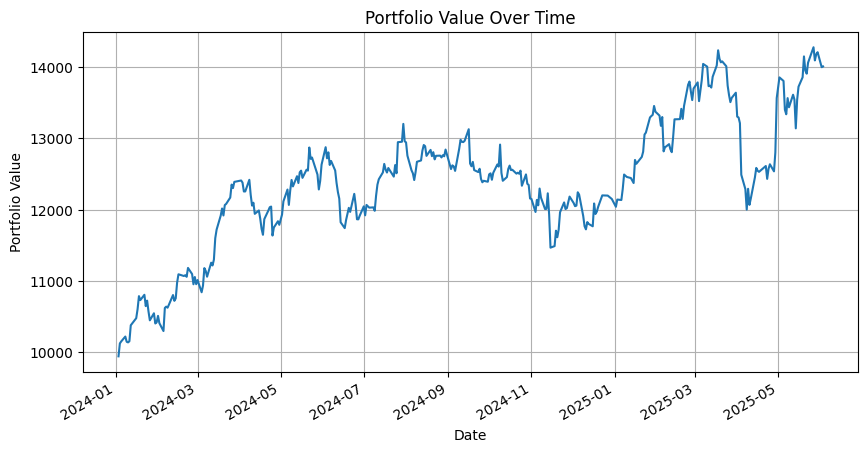

In [119]:
# Plot
plt.figure(figsize=(10, 5))
portfolio_value_series.plot()
plt.title("Portfolio Value Over Time")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.grid(True)
plt.show()

### Value at Risk (VaR) and Expected Shortfall (ES) Estimation

#### Normal assumption

In [120]:
risk_df = compute_normal_var_es(mvp_weights_df, test_returns, cov_matrices)
risk_df.head()

,VaR,ES
2024-01-03,0.042121,0.051283
2024-01-04,0.017276,0.026294
2024-01-05,0.033139,0.042270
2024-01-08,0.031150,0.040768
2024-01-09,0.044819,0.054382


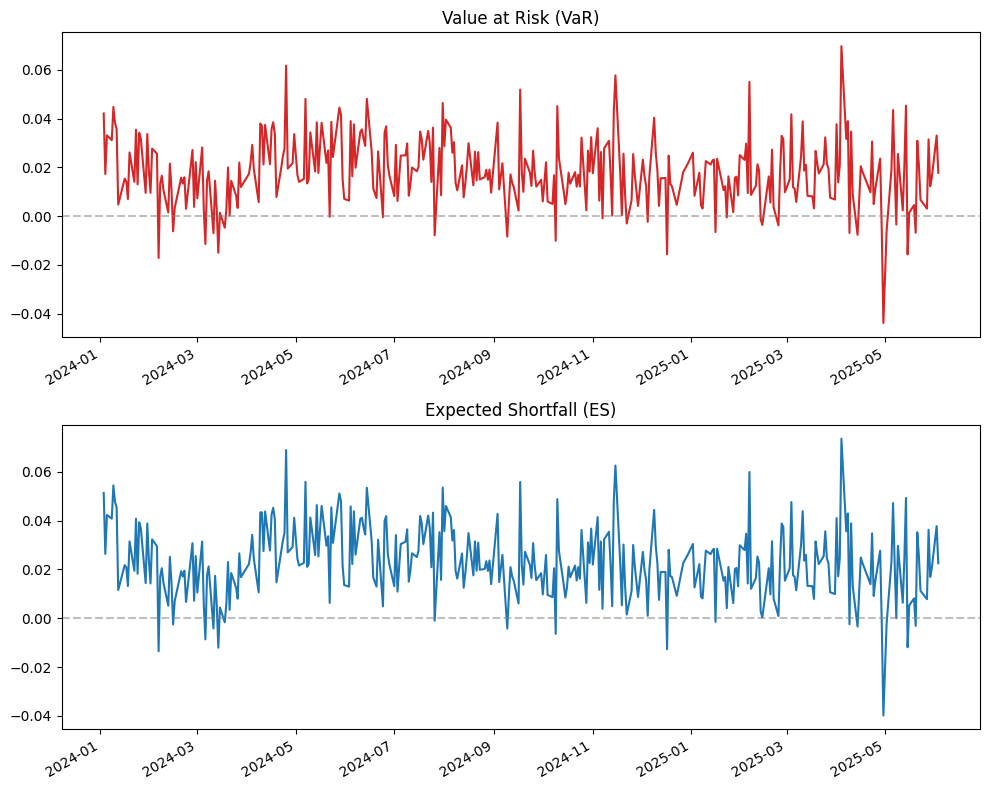

In [121]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 8))

# Plot VaR
risk_df["VaR"].plot(ax=axes[0], title="Value at Risk (VaR)", color='tab:red')
axes[0].axhline(0, linestyle="--", color="gray", alpha=0.5)

# Plot ES
risk_df["ES"].plot(ax=axes[1], title="Expected Shortfall (ES)")
axes[1].axhline(0, linestyle="--", color="gray", alpha=0.5)

plt.tight_layout()
plt.show()

#### Stress Testing (Historical)

In [122]:
# Compute portfolio returns
common_dates = test_returns.index.intersection(mvp_weights_df.index)
test_returns = test_returns.loc[common_dates]
mvp_weights_df = mvp_weights_df.loc[common_dates]

portfolio_returns = []

for i in range(len(mvp_weights_df)):
  w = np.array(mvp_weights_df.iloc[i])
  r = np.array(test_returns.iloc[i])
  portfolio_return = np.dot(w, r)
  portfolio_returns.append(portfolio_return)

portfolio_returns = pd.Series(portfolio_returns, index=mvp_weights_df.index)

In [123]:
window = int(best_params_historical[0]["window"])

VaR_series_historical, ES_series_historical = historical_var_es(portfolio_returns, window=window)

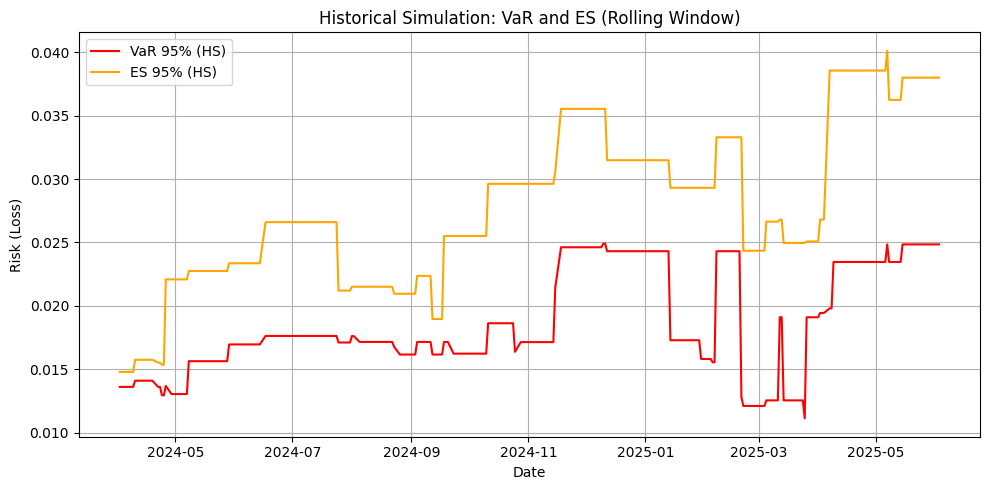

In [124]:
plt.figure(figsize=(10, 5))
plt.plot(VaR_series_historical, label="VaR 95% (HS)", color='red')
plt.plot(ES_series_historical, label="ES 95% (HS)", color='orange')
plt.title("Historical Simulation: VaR and ES (Rolling Window)")
plt.xlabel("Date")
plt.ylabel("Risk (Loss)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### Stress Amplification

In [125]:
# Parameters
window = int(best_params_stress[0]["window"])
stress_threshold = best_params_stress[0]["stress_threshold"]
stress_multiplier = best_params_stress[0]["stress_multiplier"]
confidence_level = 0.95

VaR_series_stress, ES_series_stress = stress_var_es(portfolio_returns, window, stress_threshold, stress_multiplier)

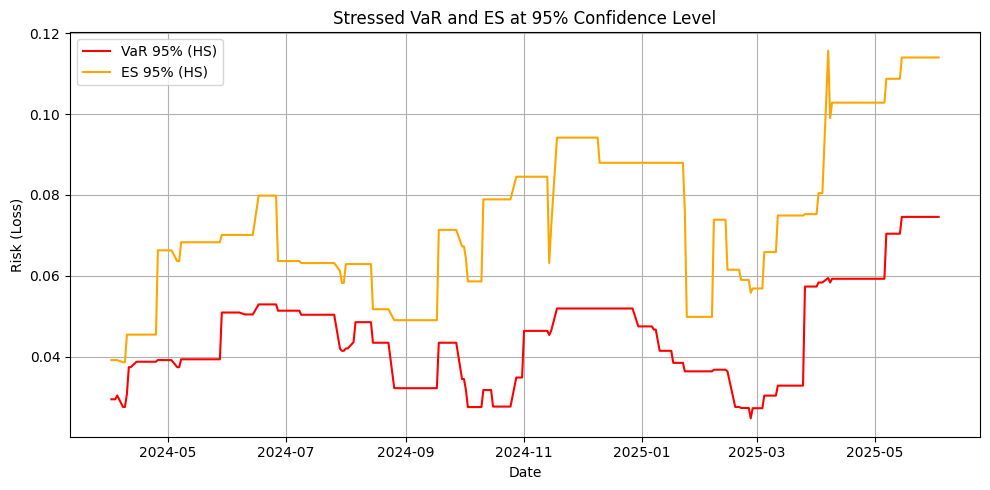

In [126]:
plt.figure(figsize=(10, 5))
plt.plot(VaR_series_stress, label="VaR 95% (HS)", color='red')
plt.plot(ES_series_stress, label="ES 95% (HS)", color='orange')
plt.title("Stressed VaR and ES at 95% Confidence Level")
plt.xlabel("Date")
plt.ylabel("Risk (Loss)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### Stress Amplification With Z-Score

In [127]:
# Parameters
window = int(best_params_z_threshold[0]["window"])
stress_multiplier = best_params_z_threshold[0]["stress_multiplier"]
z_threshold = best_params_z_threshold[0]["z_threshold"]
confidence_level = 0.95

VaR_series_stress_z_threshold, ES_series_stress_z_threshold = stressed_var_es_z_threshold(portfolio_returns, window, stress_multiplier, z_threshold)

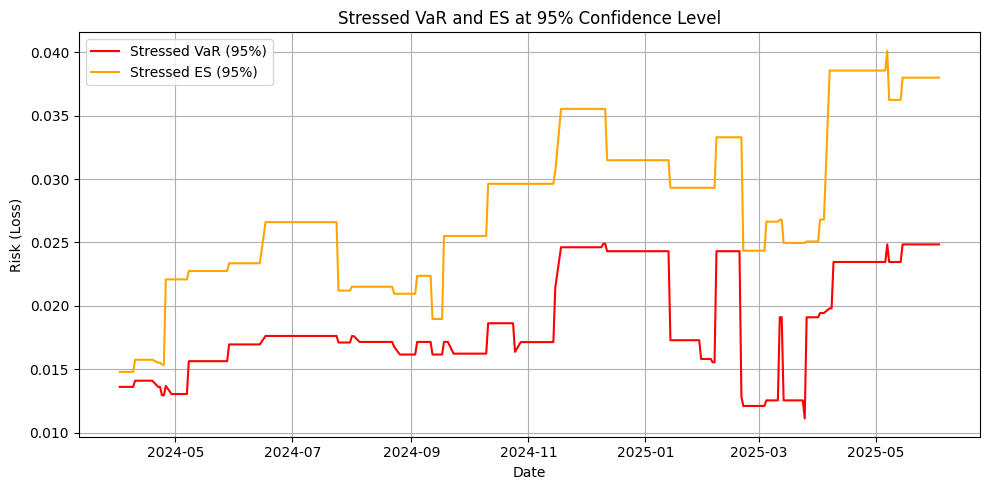

In [128]:
plt.figure(figsize=(10, 5))
plt.plot(VaR_series_stress_z_threshold, label="Stressed VaR (95%)", color='red')
plt.plot(ES_series_stress_z_threshold, label="Stressed ES (95%)", color='orange')
plt.title("Stressed VaR and ES at 95% Confidence Level")
plt.xlabel("Date")
plt.ylabel("Risk (Loss)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### LSTM

In [129]:
VaR_series_lstm, ES_series_lstm = lstm_var_es(portfolio_returns, model, loockback)

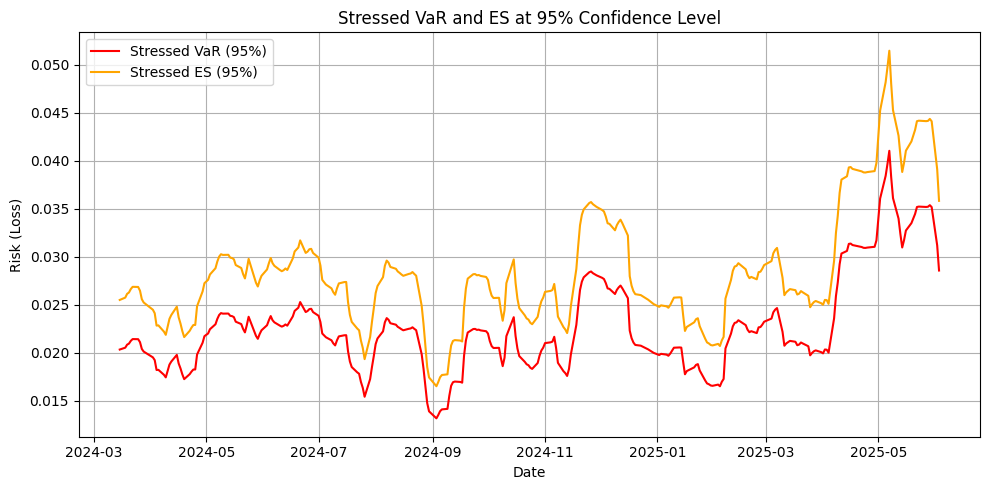

In [134]:
plt.figure(figsize=(10, 5))
plt.plot(VaR_series_lstm, label="Stressed VaR (95%)", color='red')
plt.plot(ES_series_lstm, label="Stressed ES (95%)", color='orange')
plt.title("Stressed VaR and ES at 95% Confidence Level")
plt.xlabel("Date")
plt.ylabel("Risk (Loss)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [133]:
# Collect model evaluation results
model_results = [
    {
        "Model": "Normal Distribution",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, risk_df['VaR'], risk_df['ES'])[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, risk_df['VaR'], risk_df['ES'])[1],
        "Predicted ES": evaluate_stress_model(portfolio_returns, risk_df['VaR'], risk_df['ES'])[2]
    },
    {
        "Model": "Historical",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_historical, ES_series_historical)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_historical, ES_series_historical)[1],
        "Predicted ES": evaluate_stress_model(portfolio_returns, VaR_series_historical, ES_series_historical)[2]
    },
    {
        "Model": "Stress Amplification",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_stress, ES_series_stress)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_stress, ES_series_stress)[1],
        "Predicted ES": evaluate_stress_model(portfolio_returns, VaR_series_stress, ES_series_stress)[2]
    },
    {
        "Model": "Stress Amplification (Z-Score)",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_stress_z_threshold, ES_series_stress_z_threshold)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_stress_z_threshold, ES_series_stress_z_threshold)[1],
        "Predicted ES": evaluate_stress_model(portfolio_returns, VaR_series_stress_z_threshold, ES_series_stress_z_threshold)[2]
    },
    {
        "Model": "LSTM",
        "VaR Violation Rate (%)": evaluate_stress_model(portfolio_returns, VaR_series_lstm, ES_series_lstm)[0],
        "Actual ES": evaluate_stress_model(portfolio_returns, VaR_series_lstm, ES_series_lstm)[1],
        "Predicted ES": evaluate_stress_model(portfolio_returns, VaR_series_lstm, ES_series_lstm)[2]
    }
]

# Create and format results DataFrame
results_df = pd.DataFrame(model_results)
results_df["VaR Violation Rate (%)"] = results_df["VaR Violation Rate (%)"].round(2)
results_df["Actual ES"] = results_df["Actual ES"].round(4)

# Display the the table
results_df

,Model,VaR Violation Rate (%),Actual ES,Predicted ES
0,Normal Distribution,0.00,NaN,0.023002
1,Historical,7.29,0.0266,0.027533
2,Stress Amplification,0.69,0.0338,0.073678
3,Stress Amplification (Z-Score),7.29,0.0266,0.027533
4,LSTM,3.36,0.0329,0.028303


The historical model and the Z-score stress amplification model yielded identical performance metrics on this test set. Both recorded a violation rate of 7.29%, significantly above the expected 5%, indicating that they systematically underestimated risk during this period. Although their predicted ES values were reasonably close to the actual ES, the inability to contain losses within the expected range reflects a lack of adaptability to novel stress scenarios.

The stress amplification model that uses a fixed volatility threshold exhibited the lowest violation rate (0.69%), suggesting a highly conservative approach. However, this conservatism came at the cost of accuracy: the predcted ES was substantially higher than the actual ES, revealing a tendency to overreact to perceived stress, which may result in inefficient capital allocation or overly cautious portfolio adjustments.

The LSTM model achieved the most balanced and reliable performance. With a violation rate of 3.36%, it remained within an acceptable range around the target of 5%, while the predicted ES (0.0283) was closely aligned wit the actual ES (0.0329). This indicates that the LSTM was not only effective at anticipating extreme losses, but also caplable of estimating their magnitude with good precision.



## Conclusion

The primary goal of this project was to construct a minimum variance portfolio using two assets, with the objective of minimizing exposure to financial risk while preserving adaptability to varying market conditions. To achieve this, multiple models for estimating Value at Risk and Expected Shortfall were developed, calibrated, and rigorously evaluated under both historical and stressed scenarios.

Throughout the analysis, particular emphasis was placed on the models' ability to anticipate losses during periods of elavated volatility. Traditional approaches, such as the historical and parametric models, offered simplicity and interpretability but struggled to adapt when market dynamics deviated significantly from past behavior. To overcome this limitation, stress-aware models were introduced, which aimed to enhance risk sensitivity by amplifying potential losses during turbulent periods. Among these, the z-score-based stress model offered a more statistically grounded approach to defining stress, improving adaptability without excessive conservatism.

The most promising results, however, emerged from the LSTM-based model. By leveraging sequential learning and temporal dependencies in financial time series, the LSTM demonstrated superior performance in balancing accuracy and robustness. It effectively captured the non-linear patterns of risk, adapting to evolving market regimes while maintaining alignment between predicted and realized extreme losses.

In conclusion, this project highlights the importance of using adaptive and forward-looking models in risk management. While no model can fully eliminate uncertainty, those capable of dynamically adjusting to market stress, especially models powered by machine learning, are best positioned to support more resilient portfolio strategies in increasingly complex financial environments.